# ClientCo — Prévention du churn : exploration visuelle des données

**Objectif du notebook** : comprendre le dataset transactionnel et les enjeux du use case *Prévention du churn* (UC n°1 de la priorisation d'équipe) **avant** de modéliser. Aucun modèle ici : on regarde, on mesure, on tranche des définitions.

## Ce que disent les documents du cas (synthèse)

| Sujet | Ce qu'on retient | Source |
|---|---|---|
| Entreprise | Distributeur B2B de matériaux de construction, ~15,5 Md de CA, >1 000 agences, >15 pays, >450 k clients actifs, ~200 commerciaux, marge brute ≈ 25 %. Agences = 60 % des ventes, online ≈ 0. | Key Facts, Financials |
| Sponsor | La CDO (arrivée il y a 3 mois) veut une victoire rapide pour convaincre le CEO. Elle juge le churn *faisable* (données de ventes accessibles, peu d'effectifs) et évoque **+1 % de revenu**. | CDO |
| Soutiens | Commercial Director : « impact financier majeur ». Head of Sales : « hot topic depuis des années, jamais de solution efficace », mesure difficile. Benchmark OffSupp : churn = *quick win*, mais **l'adoption par les équipes locales est le vrai défi**. | Interviews |
| Scepticisme | Sales Manager : « le churn est imprévisible, la data est trop réductrice » — mais prêt à essayer. CRM mal rempli. | Sales Manager |
| Clients | Base très hétérogène : institutions publiques (appels d'offres, action commerciale quasi impossible), acheteurs occasionnels, PME régulières, clients sous contrat long terme, grands comptes gérés centralement. | Head of Sales |
| Causes citées | Ruptures de stock et délais de livraison = **1res raisons de départ** (≈ 50 M de pertes liées aux ruptures). | Supply Chain |
| Leviers d'action | Visite : efficace mais ~3 h + 1 h de suivi. Téléphone : « le meilleur » (efficace, peu coûteux). E-mail : gratuit mais inefficace hors clients très actifs. | Sales Manager, Head of Sales |
| Données | **Uniquement des transactions** (8 colonnes), sous-ensemble des agences et clients. Aucune donnée qualitative / comportementale client. | Data team |
| Calendrier | Case Team Meeting le 20/11 ; modèle à rendre le 26/11 à 12h ; passage devant le CEO le 27/11. | Brief |

## Les questions auxquelles ce notebook doit répondre

| # | Question | Section |
|---|---|---|
| Q1 | Peut-on faire confiance aux données ? Quels pièges (retours, dates, trous) ? | 1 |
| Q2 | À quoi ressemble l'activité : canaux, agences, produits ? | 2 |
| Q3 | Qui sont les clients ? La base est-elle aussi hétérogène que dit l'interview ? | 3 |
| Q4 | **Qu'est-ce qu'un client « perdu » ?** Quel seuil d'inactivité, quelle fenêtre ? | 4 |
| Q5 | Combien de churn, et **combien de CA** est en jeu ? (vs hypothèses du chiffrage : 5 / 8 / 12 % du CA) | 5 |
| Q6 | Les nouveaux clients restent-ils ? (rétention par cohorte) | 6 |
| Q7 | **Où** le churn se concentre-t-il (segments, canal, agence) ? | 7 |
| Q8 | Y a-t-il des **signaux avant-coureurs** exploitables dans les transactions seules ? | 8 |
| Q9 | Quelle liste d'action est réaliste pour ~200 commerciaux, et quel est le « score à battre » ? | 9 |

> **Conventions** : « M » = millions dans la devise du dataset (non précisée : Key Facts parle de $, Financials d'EUR). *Jour d'achat* = couple (client, date_order) avec ventes positives — le dataset n'a pas d'identifiant de commande.

## 0. Setup

Le CSV fait **4,2 Go / 63 M de lignes** : impossible à charger dans pandas sur un laptop. On utilise **DuckDB** : conversion unique en Parquet (~1 min, colonnée et compressée), puis on agrège en SQL et on ne rapatrie dans pandas que de petites tables pour tracer.

In [1]:
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = next((p for p in (ROOT / "data" / "dataset_sales_2026.csv", ROOT / "dataset_sales_2026.csv") if p.exists()), ROOT / "dataset_sales_2026.csv")
PARQUET = ROOT / "data" / "sales.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
(ROOT / "data").mkdir(exist_ok=True)
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).fetchdf()


if not PARQUET.exists():
    t0 = time.time()
    con.execute(f"""
        COPY (SELECT * FROM read_csv('{CSV}', delim=';', header=true, columns={{
            'date_order':'DATE','date_invoice':'DATE','product_id':'BIGINT','client_id':'BIGINT',
            'sales_net':'DOUBLE','quantity':'DOUBLE','order_channel':'VARCHAR','branch_id':'BIGINT'}}))
        TO '{PARQUET}' (FORMAT parquet, COMPRESSION zstd)""")
    print(f"CSV -> Parquet en {time.time() - t0:.0f}s")

con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
q("SELECT * FROM sales LIMIT 5")

,date_order,date_invoice,product_id,client_id,sales_net,quantity,order_channel,branch_id
0,2022-09-25,2022-09-25,2376333,188502,155.443,3.000,online,2732
1,2022-09-25,2022-09-25,2520527,835089,16.394,3.000,at the store,10279
2,2022-09-25,2022-09-25,2536756,1977896,365.766,21.000,online,6184
3,2022-09-25,2022-09-25,3028673,598816,8.599,201.000,at the store,4200
4,2022-09-25,2022-09-25,203377,2086861,"1,093.374",3.000,by phone,7051


### Paramètres de la « photo » (modifiables)

Pour parler de churn il faut une **date d'observation T** : on regarde le passé (< T) pour décrire un client, et le futur (≥ T) pour savoir s'il est parti.
- `BASE_DAYS` : population suivie = clients ayant acheté au moins une fois dans les `BASE_DAYS` derniers jours avant T.
- `HORIZON` : un client est *churné* s'il n'achète plus pendant `HORIZON` jours après T.

Le dataset s'arrête le 22/09/2024 ; la dernière photo possible avec 180 jours d'horizon est donc le 22/03/2024. La section 4 justifie ces choix.

In [2]:
T_SNAP = "2024-03-22"   # date de la photo principale
BASE_DAYS = 180         # population = clients actifs dans les 180 derniers jours
HORIZON = 180           # churn = aucun achat pendant les 180 jours suivants
N_REPS = 200            # nombre de commerciaux (Head of Sales)

### Style graphique
Palette catégorielle validée (ordre fixe : une couleur = une entité), rampe bleue pour les magnitudes, gris neutres pour la structure, orange pour « ce qui alerte ». Fond clair pour que les figures restent lisibles quel que soit le thème de l'éditeur.

In [3]:
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)
NEUTRAL = "#b9b8b0"

# Une couleur par canal, identique dans tout le notebook
CHANNEL_COLOR = {"by phone": C["orange"], "at the store": C["blue"], "online": C["aqua"],
                 "during the visit of a sales rep": C["yellow"], "other": C["magenta"]}
CHANNEL_LABEL = {"by phone": "Téléphone", "at the store": "En agence", "online": "En ligne",
                 "during the visit of a sales rep": "Visite commercial", "other": "Autre"}

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False, "legend.fontsize": 9,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
})


def headline(fig, title, sub=None):
    """Action title (the takeaway) + optional muted subtitle, left-aligned above the figure."""
    h = fig.get_figheight()
    fig.text(0.005, 1 + (0.30 if sub else 0.12) / h, title, fontsize=13, fontweight="bold", color=INK, ha="left", va="bottom")
    if sub:
        fig.text(0.005, 1 + 0.08 / h, sub, fontsize=9.5, color=INK2, ha="left", va="bottom")


def fmt_m(x, _=None):
    return f"{x / 1e6:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    f = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def label_end(ax, x, y, text, dx=6, **kw):
    """Direct label at the end of a line (secondary ink, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(dx, 0), textcoords="offset points", va="center", color=INK2, fontsize=9, **kw)


def pct(x, d=1):
    return f"{100 * x:.{d}f} %"

## 1. Qualité et structure des données

**Question Q1** — avant toute analyse de churn, on vérifie que la matière première tient la route. Un client « inactif » peut n'être qu'un artefact de données (retours, trous de calendrier, dates décalées).

In [4]:
kpi = q("""
SELECT count(*)                                  AS lignes,
       count(DISTINCT client_id)                 AS clients,
       count(DISTINCT product_id)                AS produits,
       count(DISTINCT branch_id)                 AS agences,
       min(date_order)                           AS date_order_min,
       max(date_order)                           AS date_order_max,
       min(date_invoice)                         AS date_invoice_min,
       max(date_invoice)                         AS date_invoice_max,
       sum(sales_net)                            AS ca_net,
       sum(greatest(sales_net, 0))               AS ca_positif,
       sum(least(sales_net, 0))                  AS retours
FROM sales""").iloc[0]

quality = q("""
SELECT
  count(*) FILTER (WHERE sales_net < 0)                          AS lignes_negatives,
  count(*) FILTER (WHERE sales_net = 0)                          AS lignes_nulles,
  count(*) FILTER (WHERE date_invoice IS NULL)                   AS facture_manquante,
  count(*) FILTER (WHERE date_invoice < date_order)              AS facture_avant_commande,
  count(*) FILTER (WHERE date_invoice > date_order)              AS facture_apres_commande,
  count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) > 30)  AS facture_plus_30j,
  count(*) FILTER (WHERE date_invoice > DATE '2024-09-22')       AS facture_apres_fin_periode,
  min(quantity)                                                  AS quantite_min,
  quantile_cont(quantity, 0.5)                                   AS quantite_mediane,
  quantile_cont(sales_net, 0.5) FILTER (WHERE sales_net > 0)     AS ligne_mediane
FROM sales""").iloc[0]
n = kpi["lignes"]

print(f"Période de commande  : {kpi['date_order_min']:%d/%m/%Y} -> {kpi['date_order_max']:%d/%m/%Y}  (2 ans exactement)")
print(f"Période de facture   : {kpi['date_invoice_min']:%d/%m/%Y} -> {kpi['date_invoice_max']:%d/%m/%Y}  (déborde largement)")
print(f"Volumétrie           : {n:,.0f} lignes · {kpi['clients']:,.0f} clients · {kpi['produits']:,.0f} produits · {kpi['agences']:,.0f} agences")
print(f"CA net / positif     : {kpi['ca_net'] / 1e9:,.2f} Md / {kpi['ca_positif'] / 1e9:,.2f} Md  (retours = {kpi['retours'] / 1e6:,.0f} M, {abs(kpi['retours']) / kpi['ca_positif']:.1%} du CA positif)")
print(f"Lignes < 0 / = 0     : {quality['lignes_negatives'] / n:.1%} / {quality['lignes_nulles'] / n:.1%}")
print(f"Facture ≠ commande   : {quality['facture_apres_commande'] / n:.1%} facturées après la commande ; {quality['facture_plus_30j'] / n:.1%} à plus de 30 jours ; {quality['facture_avant_commande']:,.0f} avant la commande")
print(f"Quantité             : min {quality['quantite_min']:.0f} (jamais < 3), médiane {quality['quantite_mediane']:.0f} · ligne médiane {quality['ligne_mediane']:.0f}")

Période de commande  : 22/09/2022 -> 22/09/2024  (2 ans exactement)
Période de facture   : 12/10/2021 -> 13/07/2026  (déborde largement)
Volumétrie           : 63,319,315 lignes · 170,589 clients · 607,418 produits · 582 agences
CA net / positif     : 9.37 Md / 9.94 Md  (retours = -577 M, 5.8% du CA positif)
Lignes < 0 / = 0     : 3.8% / 3.8%
Facture ≠ commande   : 29.2% facturées après la commande ; 4.1% à plus de 30 jours ; 99 avant la commande
Quantité             : min 3 (jamais < 3), médiane 5 · ligne médiane 52


**À retenir**
- Les dates de commande couvrent bien **2 ans pile** (22/09/2022 → 22/09/2024) alors que le fichier s'appelle `…_2026.csv` : le décalage de +5 ans prévu dans `exploratory_and_data_update.ipynb` n'est **pas** appliqué dans ce fichier. À clarifier avec l'équipe pour ne pas mélanger les années dans le deck.
- ~4 % de lignes **négatives** (retours / avoirs) et ~4 % de lignes à **zéro** : une ligne négative n'est pas un achat. Un client dont la dernière « activité » est un avoir est en réalité déjà parti.
- `date_invoice` est **bruité** (jusqu'en 2026, 29 % de lignes facturées après la commande) : on prendra `date_order` comme date d'activité.
- La quantité n'est jamais < 3, même pour les lignes négatives : la quantité ne signale pas les retours, le signe de `sales_net` oui.

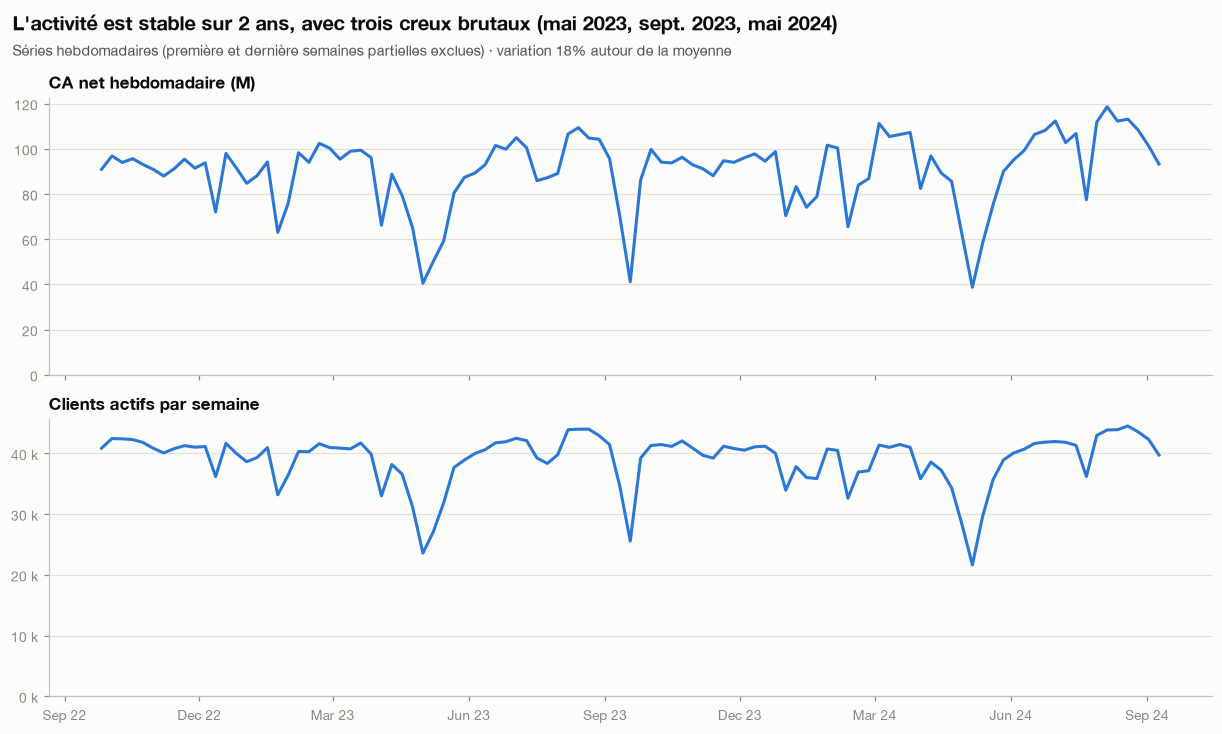

In [5]:
weekly = q("""
SELECT date_trunc('week', date_order) AS week, count(*) AS lignes, sum(sales_net) AS ca,
       count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1 ORDER BY 1""")
weekly = weekly.iloc[1:-1]  # first and last weeks are partial

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(weekly["week"], weekly["ca"], color=C["blue"])
axes[0].set_title("CA net hebdomadaire (M)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
axes[1].plot(weekly["week"], weekly["clients"], color=C["blue"])
axes[1].set_title("Clients actifs par semaine")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
for ax in axes:
    ax.set_ylim(bottom=0)
cv = weekly["ca"].std() / weekly["ca"].mean()
headline(fig, "L'activité est stable sur 2 ans, avec trois creux brutaux (mai 2023, sept. 2023, mai 2024)",
         f"Séries hebdomadaires (première et dernière semaines partielles exclues) · variation {cv:.0%} autour de la moyenne")
plt.show()

Le calendrier est **continu** (731 jours, aucun trou) mais trois **creux brutaux** divisent l'activité par ~2 : semaines du **1er et 8 mai 2023**, du **18 septembre 2023** et du **6 mai 2024** (jours fériés en France pour mai ; septembre 2023 est inexpliqué — à demander au client). Ils comptent pour le churn : un client qui n'achète pas pendant un creux n'est pas forcément perdu. Regardons aussi le profil par jour de semaine :

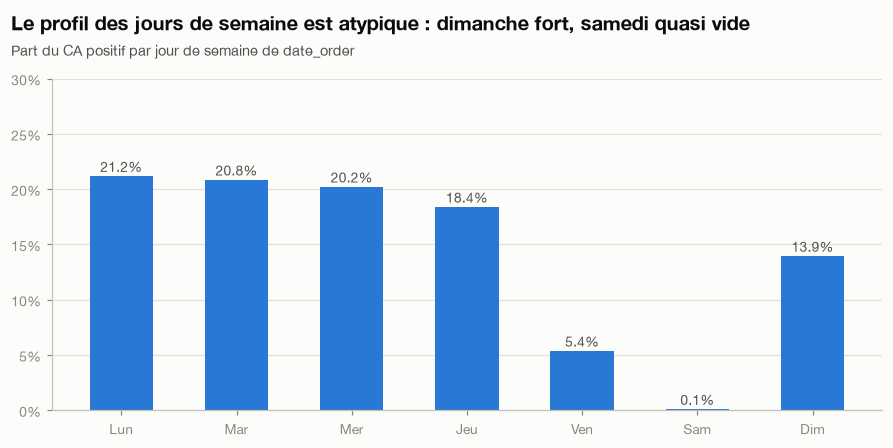

In [6]:
dow = q("""
SELECT isodow(date_order) AS dow, count(*) AS lignes, sum(greatest(sales_net, 0)) AS ca
FROM sales GROUP BY 1 ORDER BY 1""")
labels = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
ax.bar(dow["dow"], dow["ca"] / dow["ca"].sum(), width=0.55, color=C["blue"])
for x, v in zip(dow["dow"], dow["ca"] / dow["ca"].sum()):
    ax.text(x, v + 0.004, f"{v:.1%}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(dow["dow"], labels)
pct_axis(ax)
ax.set_ylim(0, 0.3)
headline(fig, "Le profil des jours de semaine est atypique : dimanche fort, samedi quasi vide",
         "Part du CA positif par jour de semaine de date_order")
plt.show()

Pour un distributeur B2B on attendrait des ventes du lundi au vendredi. Ici le **dimanche pèse ~14 % et le samedi ~0 %** : les dates ont très probablement été **décalées / anonymisées**. Conséquence : ne **pas** construire de variable « jour de semaine » ; les mois et les écarts entre dates restent exploitables.

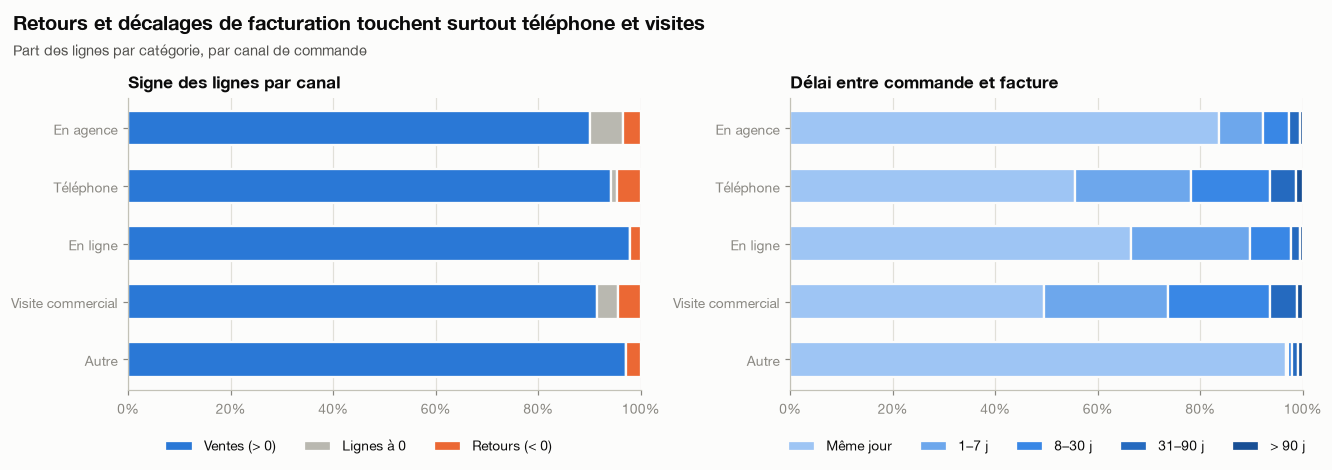

In [7]:
sign_ch = q("""
SELECT order_channel, count(*) FILTER (WHERE sales_net > 0) AS pos, count(*) FILTER (WHERE sales_net = 0) AS zero,
       count(*) FILTER (WHERE sales_net < 0) AS neg
FROM sales GROUP BY 1""").set_index("order_channel")
lag = q("""
SELECT order_channel,
       count(*) FILTER (WHERE date_invoice <= date_order)                                    AS same_day,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 1 AND 7)    AS d1_7,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 8 AND 30)   AS d8_30,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) BETWEEN 31 AND 90)  AS d31_90,
       count(*) FILTER (WHERE date_diff('day', date_order, date_invoice) > 90)               AS d90p
FROM sales GROUP BY 1""").set_index("order_channel")
order = ["at the store", "by phone", "online", "during the visit of a sales rep", "other"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
# left: sign of lines per channel
share = sign_ch.loc[order].div(sign_ch.loc[order].sum(axis=1), axis=0)
y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for col, colr, lab in [("pos", C["blue"], "Ventes (> 0)"), ("zero", NEUTRAL, "Lignes à 0"), ("neg", C["orange"], "Retours (< 0)")]:
    axes[0].barh(y, share[col], left=left, color=colr, height=0.6, label=lab, edgecolor=SURF, linewidth=1.5)
    left += share[col].to_numpy()
axes[0].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[0], "x")
axes[0].set_xlim(0, 1)
axes[0].grid(axis="x")
axes[0].grid(axis="y", visible=False)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.12))
axes[0].set_title("Signe des lignes par canal")
# right: invoice lag
shl = lag.loc[order].div(lag.loc[order].sum(axis=1), axis=0)
left = np.zeros(len(order))
for col, colr, lab in zip(["same_day", "d1_7", "d8_30", "d31_90", "d90p"], SEQ[1:6], ["Même jour", "1–7 j", "8–30 j", "31–90 j", "> 90 j"]):
    axes[1].barh(y, shl[col], left=left, color=colr, height=0.6, label=lab, edgecolor=SURF, linewidth=1.5)
    left += shl[col].to_numpy()
axes[1].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[1], "x")
axes[1].set_xlim(0, 1)
axes[1].grid(axis="x")
axes[1].grid(axis="y", visible=False)
axes[1].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[1].set_title("Délai entre commande et facture")
headline(fig, "Retours et décalages de facturation touchent surtout téléphone et visites",
         "Part des lignes par catégorie, par canal de commande")
plt.show()

Le **retard de facturation** (jusqu'à 3 ans) est massif pour le téléphone et la visite commerciale (~45-50 % des lignes facturées après la commande) et rare en agence : c'est peut-être un proxy de **commandes livrées en différé** (ruptures, délais — les 1res causes de départ selon la Supply Chain). On le testera comme signal en section 8.

### Décisions de nettoyage retenues pour la suite

| Décision | Raison |
|---|---|
| Date d'activité = `date_order` | `date_invoice` déborde jusqu'en 2026 |
| **Jour d'achat** = (client, date_order) avec ventes positives > 0 | pas d'id de commande ; les jours avec seulement des avoirs ne sont pas des achats |
| Les retours restent dans les CA nets mais comptent comme **signal**, pas comme activité | un avoir ≠ réengagement |
| Pas de variable jour-de-semaine | dates décalées |
| 1 seule ligne dupliquée : ignorée | négligeable |

In [8]:
# Daily client x day table (one pass over the 63M lines), then purchase days only.
t0 = time.time()
con.execute("""
CREATE OR REPLACE TABLE cd AS
SELECT client_id, date_order AS d,
       sum(sales_net)                                   AS rev_net,
       sum(greatest(sales_net, 0))                      AS rev_pos,
       sum(least(sales_net, 0))                         AS rev_neg,
       count(*)                                         AS n_lines,
       count(DISTINCT product_id)                       AS n_prod,
       arg_max(branch_id, greatest(sales_net, 0))       AS branch_id,
       arg_max(order_channel, greatest(sales_net, 0))   AS channel,
       avg(least(greatest(date_diff('day', date_order, date_invoice), 0), 365)) AS lag_mean
FROM sales GROUP BY client_id, date_order""")
con.execute("CREATE OR REPLACE TABLE bd AS SELECT * FROM cd WHERE rev_pos > 0")
cnt = q("SELECT (SELECT count(*) FROM cd) AS client_days, (SELECT count(*) FROM bd) AS purchase_days").iloc[0]
print(f"{cnt['client_days']:,.0f} (client, jour) · dont {cnt['purchase_days']:,.0f} jours d'achat · construit en {time.time() - t0:.0f}s")

7,955,289 (client, jour) · dont 7,953,336 jours d'achat · construit en 16s


### Distribution des montants et quantités
Les lignes sont **extrêmement asymétriques** : on trace en échelle log.

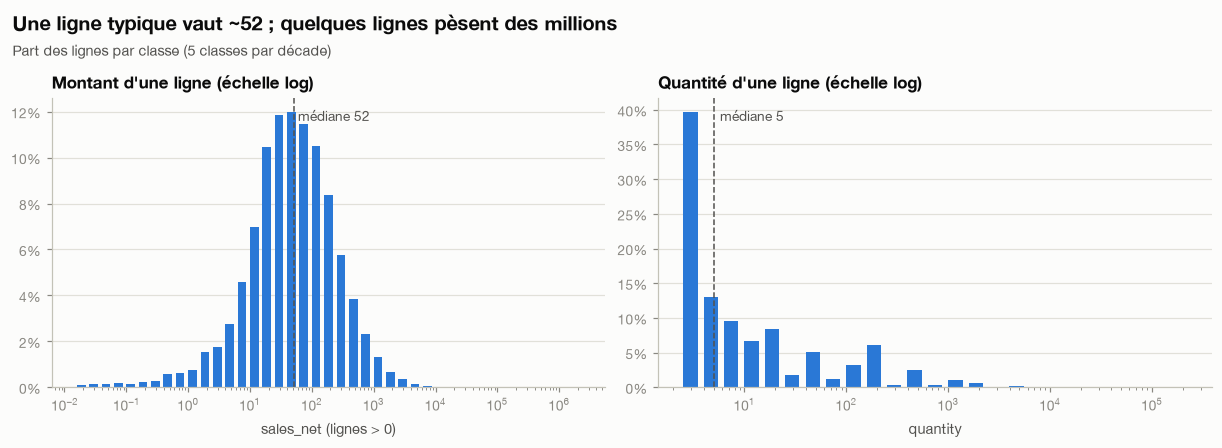

In [9]:
bins_sales = q("""
SELECT floor(log10(sales_net) * 5) / 5 AS b, count(*) AS n FROM sales WHERE sales_net > 0 GROUP BY 1 ORDER BY 1""")
bins_qty = q("SELECT floor(log10(quantity) * 5) / 5 AS b, count(*) AS n FROM sales GROUP BY 1 ORDER BY 1")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for ax, d, ttl, med in [(axes[0], bins_sales, "Montant d'une ligne (échelle log)", quality["ligne_mediane"]),
                        (axes[1], bins_qty, "Quantité d'une ligne (échelle log)", quality["quantite_mediane"])]:
    ax.bar(10 ** d["b"], d["n"] / d["n"].sum(), width=10 ** d["b"] * 0.38, color=C["blue"], align="edge")
    ax.set_xscale("log")
    pct_axis(ax)
    ax.axvline(med, color=INK2, lw=1, ls="--")
    ax.text(med * 1.15, ax.get_ylim()[1] * 0.92, f"médiane {med:,.0f}", color=INK2, fontsize=9)
    ax.set_title(ttl)
axes[0].set_xlabel("sales_net (lignes > 0)")
axes[1].set_xlabel("quantity")
headline(fig, f"Une ligne typique vaut ~{quality['ligne_mediane']:,.0f} ; quelques lignes pèsent des millions",
         "Part des lignes par classe (5 classes par décade)")
plt.show()

## 2. Vue d'ensemble de l'activité

**Question Q2** — où se fait le chiffre d'affaires ? Cela conditionne les **canaux d'action** possibles pour une campagne de rétention.

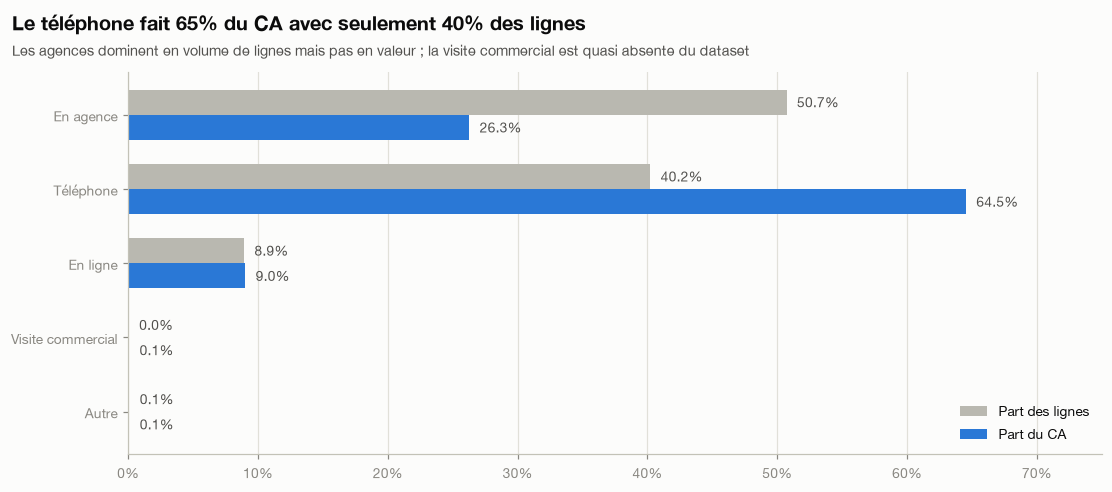

,clients,part_clients,ca_par_ligne
En agence,146857,0.861,81.366
Téléphone,135602,0.795,252.016
En ligne,21352,0.125,158.744
Visite commercial,1203,0.007,266.992
Autre,8811,0.052,156.407


In [10]:
ch = q("""
SELECT order_channel, count(*) AS lignes, sum(greatest(sales_net, 0)) AS ca, count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1""").set_index("order_channel").loc[order]
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
y = np.arange(len(order))[::-1]
h = 0.34
ax.barh(y + h / 2, ch["lignes"] / ch["lignes"].sum(), height=h, color=NEUTRAL, label="Part des lignes")
ax.barh(y - h / 2, ch["ca"] / ch["ca"].sum(), height=h, color=C["blue"], label="Part du CA")
for yi, a, b in zip(y, ch["lignes"] / ch["lignes"].sum(), ch["ca"] / ch["ca"].sum()):
    ax.text(a + 0.008, yi + h / 2, f"{a:.1%}", va="center", fontsize=9, color=INK2)
    ax.text(b + 0.008, yi - h / 2, f"{b:.1%}", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(ax, "x")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.75)
ax.legend(loc="lower right")
headline(fig, f"Le téléphone fait {ch.loc['by phone', 'ca'] / ch['ca'].sum():.0%} du CA avec seulement {ch.loc['by phone', 'lignes'] / ch['lignes'].sum():.0%} des lignes",
         "Les agences dominent en volume de lignes mais pas en valeur ; la visite commercial est quasi absente du dataset")
plt.show()
ch_tbl = ch.assign(ca_par_ligne=ch["ca"] / ch["lignes"], part_clients=ch["clients"] / kpi["clients"])[["clients", "part_clients", "ca_par_ligne"]]
ch_tbl.index = [CHANNEL_LABEL[c] for c in ch_tbl.index]
ch_tbl

**Lecture** : contrairement à l'image « 60 % des ventes en agence » des Key Facts, **le téléphone est le premier canal en valeur** dans cet extrait, et **l'en-ligne pèse ~9 % du CA** alors que les interviews et les Key Facts le disent « quasi nul ». La **visite commercial représente 0,05 % des lignes** pour ~200 commerciaux : soit les visites sont mal saisies dans le système (cohérent avec « CRM peu rempli »), soit elles se concrétisent via un autre canal. Conséquence directe pour le churn : **on ne pourra pas mesurer dans ces données l'effet d'une visite**, il faudra un pilote avec groupe témoin.

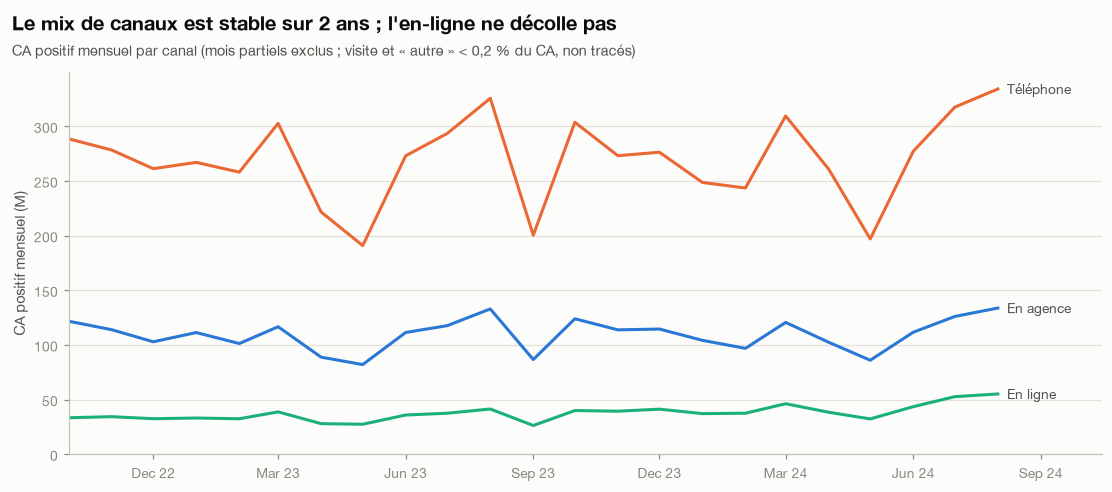

In [11]:
monthly_ch = q("""
SELECT date_trunc('month', date_order) AS m, order_channel, sum(greatest(sales_net, 0)) AS ca
FROM sales GROUP BY 1, 2 ORDER BY 1""")
monthly_ch = monthly_ch[(monthly_ch["m"] > "2022-09-30") & (monthly_ch["m"] < "2024-09-01")]
piv = monthly_ch.pivot(index="m", columns="order_channel", values="ca")[order]
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
for col in ["by phone", "at the store", "online"]:
    ax.plot(piv.index, piv[col], color=CHANNEL_COLOR[col])
    label_end(ax, piv.index[-1], piv[col].iloc[-1], CHANNEL_LABEL[col])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(piv.index[0], piv.index[-1] + pd.Timedelta(days=75))
ax.set_ylabel("CA positif mensuel (M)")
headline(fig, "Le mix de canaux est stable sur 2 ans ; l'en-ligne ne décolle pas",
         "CA positif mensuel par canal (mois partiels exclus ; visite et « autre » < 0,2 % du CA, non tracés)")
plt.show()

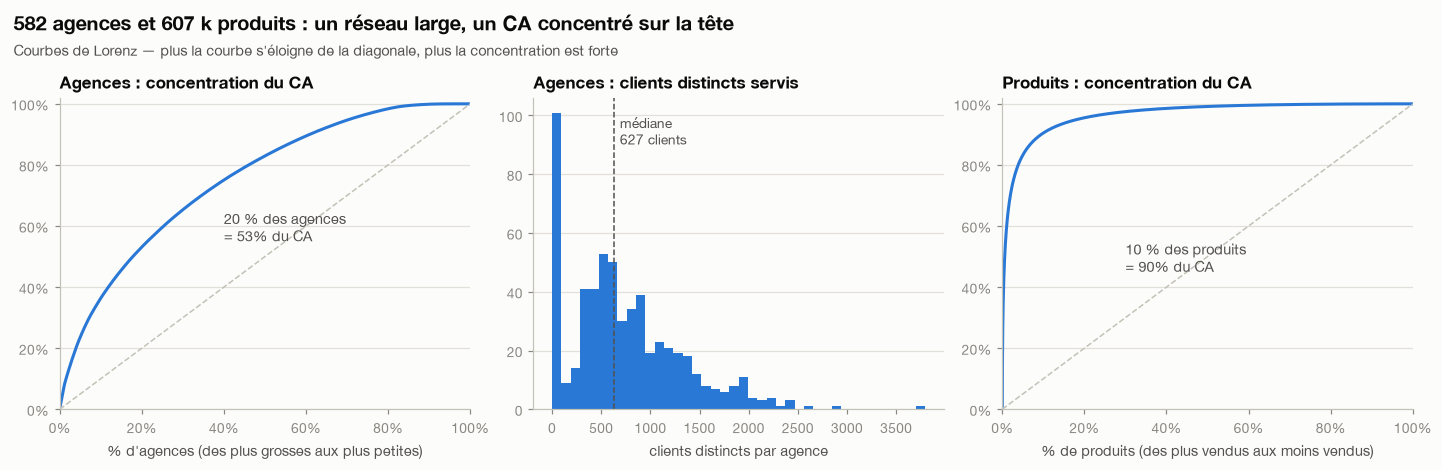

In [12]:
br = q("""
SELECT branch_id, sum(greatest(sales_net, 0)) AS ca, count(DISTINCT client_id) AS clients
FROM sales GROUP BY 1 ORDER BY ca DESC""")
br["cum_ca"] = br["ca"].cumsum() / br["ca"].sum()
br["rank_share"] = np.arange(1, len(br) + 1) / len(br)
prod = q("""
SELECT product_id, sum(greatest(sales_net, 0)) AS ca FROM sales GROUP BY 1 ORDER BY ca DESC""")
prod["cum_ca"] = prod["ca"].cumsum() / prod["ca"].sum()
prod["rank_share"] = np.arange(1, len(prod) + 1) / len(prod)


def at(df, p):
    return df.loc[df["rank_share"] <= p, "cum_ca"].iloc[-1]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
axes[0].plot(br["rank_share"], br["cum_ca"], color=C["blue"])
axes[0].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[0].set_title("Agences : concentration du CA")
axes[0].set_xlabel("% d'agences (des plus grosses aux plus petites)")
axes[0].text(0.4, 0.55, f"20 % des agences\n= {at(br, 0.2):.0%} du CA", fontsize=9.5, color=INK2)
axes[1].hist(br["clients"], bins=40, color=C["blue"])
axes[1].axvline(br["clients"].median(), color=INK2, lw=1, ls="--")
axes[1].text(br["clients"].median() * 1.1, axes[1].get_ylim()[1] * 0.85, f"médiane\n{br['clients'].median():,.0f} clients", fontsize=9, color=INK2)
axes[1].set_title("Agences : clients distincts servis")
axes[1].set_xlabel("clients distincts par agence")
axes[1].grid(axis="x", visible=False)
axes[2].plot(prod["rank_share"], prod["cum_ca"], color=C["blue"])
axes[2].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[2].set_title("Produits : concentration du CA")
axes[2].set_xlabel("% de produits (des plus vendus aux moins vendus)")
axes[2].text(0.3, 0.45, f"10 % des produits\n= {at(prod, 0.1):.0%} du CA", fontsize=9.5, color=INK2)
for ax in (axes[0], axes[2]):
    pct_axis(ax)
    pct_axis(ax, "x")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
headline(fig, f"{kpi['agences']:,.0f} agences et {kpi['produits'] / 1e3:,.0f} k produits : un réseau large, un CA concentré sur la tête",
         "Courbes de Lorenz — plus la courbe s'éloigne de la diagonale, plus la concentration est forte")
plt.show()

**Lecture** : ~**100 des 582 « agences » servent moins de 50 clients** (alors que la médiane est de ~630) tout en réalisant ~120 M de CA, quasi exclusivement **par téléphone**. Ce ne sont probablement pas des points de vente physiques (centres d'appels, comptes clés centralisés ?). Un client est aussi **rarement fidèle à une seule agence** (section 3) : l'agence est un attribut fragile pour piloter le churn. À confirmer avec la Data team.

## 3. Qui sont les clients ?

**Question Q3** — le Head of Sales décrit une base « large et diverse » : acheteurs occasionnels, PME régulières, grands comptes. Si c'est vrai dans les données, **un seul modèle et une seule définition de churn ne tiendront pas** : il faudra raisonner par rythme d'achat.

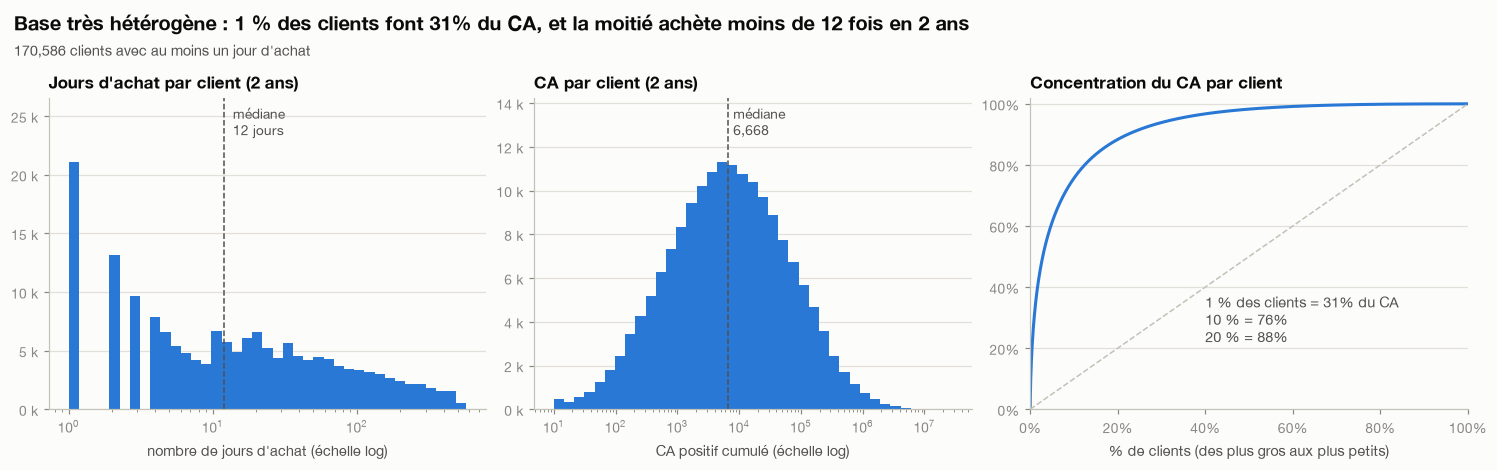

In [13]:
cl = q("""
SELECT client_id, min(d) AS first_d, max(d) AS last_d, count(*) AS n_days,
       sum(rev_pos) AS rev_pos, sum(rev_net) AS rev_net, -sum(rev_neg) / sum(rev_pos) AS ret_share,
       count(DISTINCT branch_id) AS n_branch, count(DISTINCT channel) AS n_channel, mode(channel) AS channel
FROM bd GROUP BY 1""")
FREQ2Y_BINS = [0, 1, 3, 11, 35, 103, np.inf]
FREQ2Y_LABELS = ["1 achat", "2–3", "4–11", "12–35", "36–103", "104+"]
cl["freq_class"] = pd.cut(cl["n_days"], FREQ2Y_BINS, labels=FREQ2Y_LABELS)

s = cl.sort_values("rev_pos", ascending=False).reset_index(drop=True)
s["cum"] = s["rev_pos"].cumsum() / s["rev_pos"].sum()
s["rank"] = (np.arange(len(s)) + 1) / len(s)
top = {p: s.loc[s["rank"] <= p, "cum"].iloc[-1] for p in (0.01, 0.05, 0.10, 0.20)}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6), constrained_layout=True)
b = np.logspace(0, np.log10(cl["n_days"].max()), 40)
axes[0].hist(cl["n_days"], bins=b, color=C["blue"])
axes[0].set_xscale("log")
axes[0].set_ylim(top=axes[0].get_ylim()[1] * 1.2)
axes[0].axvline(cl["n_days"].median(), color=INK2, ls="--", lw=1)
axes[0].text(cl["n_days"].median() * 1.15, axes[0].get_ylim()[1] * 0.88, f"médiane\n{cl['n_days'].median():.0f} jours", fontsize=9, color=INK2)
axes[0].set_title("Jours d'achat par client (2 ans)")
axes[0].set_xlabel("nombre de jours d'achat (échelle log)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
b = np.logspace(1, np.log10(cl["rev_pos"].max()), 40)
axes[1].hist(cl["rev_pos"].clip(lower=10), bins=b, color=C["blue"])
axes[1].set_xscale("log")
axes[1].set_ylim(top=axes[1].get_ylim()[1] * 1.2)
axes[1].axvline(cl["rev_pos"].median(), color=INK2, ls="--", lw=1)
axes[1].text(cl["rev_pos"].median() * 1.2, axes[1].get_ylim()[1] * 0.88, f"médiane\n{cl['rev_pos'].median():,.0f}", fontsize=9, color=INK2)
axes[1].set_title("CA par client (2 ans)")
axes[1].set_xlabel("CA positif cumulé (échelle log)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
axes[2].plot(s["rank"], s["cum"], color=C["blue"])
axes[2].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[2].text(0.4, 0.22, f"1 % des clients = {top[0.01]:.0%} du CA\n10 % = {top[0.10]:.0%}\n20 % = {top[0.20]:.0%}", fontsize=9.5, color=INK2)
axes[2].set_title("Concentration du CA par client")
axes[2].set_xlabel("% de clients (des plus gros aux plus petits)")
for ax_ in (axes[2],):
    pct_axis(ax_)
    pct_axis(ax_, "x")
    ax_.set_xlim(0, 1)
    ax_.set_ylim(0, 1.02)
for ax_ in axes[:2]:
    ax_.grid(axis="x", visible=False)
headline(fig, f"Base très hétérogène : 1 % des clients font {top[0.01]:.0%} du CA, et la moitié achète moins de {cl['n_days'].median():.0f} fois en 2 ans",
         f"{len(cl):,.0f} clients avec au moins un jour d'achat")
plt.show()

La distribution confirme l'interview : une très longue traîne de petits clients occasionnels et une **minorité de gros comptes qui concentre l'essentiel du CA**. Pour le churn, cela change tout : *perdre 1 000 petits clients n'a pas le même coût que perdre 10 grands comptes*, et une métrique en « nombre de clients » mentira. **Il faudra pondérer par le CA** (ou segmenter).

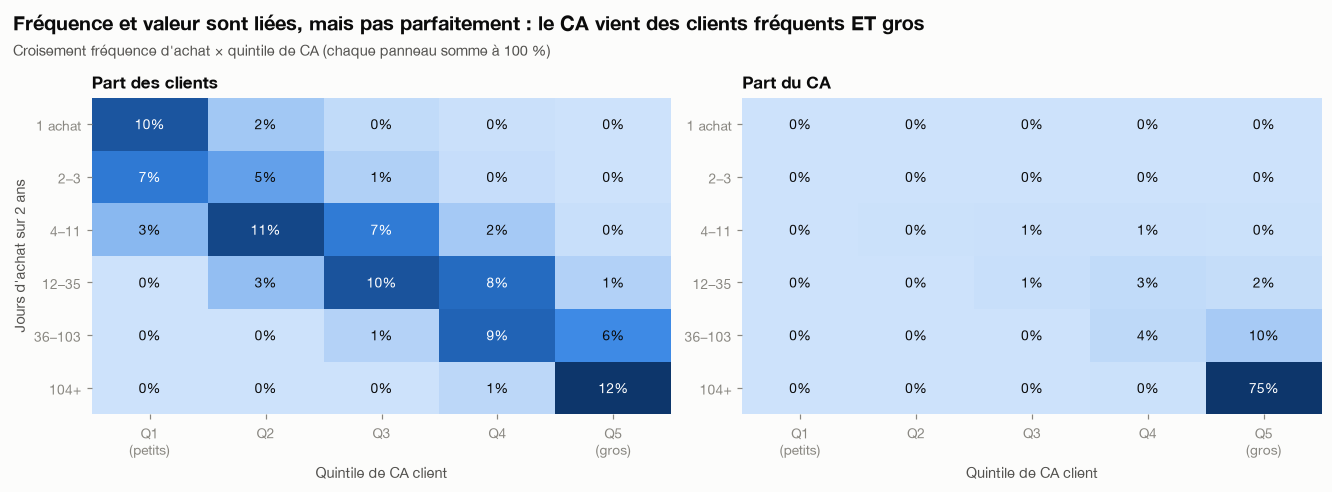

,clients,part_clients,part_ca,ca_moyen_par_client
freq_class,,,,
1 achat,21087,0.124,0.003,"1,277.260"
2–3,22837,0.134,0.006,"2,411.691"
4–11,39394,0.231,0.022,"5,628.784"
12–35,37530,0.220,0.068,"17,939.981"
36–103,27167,0.159,0.145,"52,982.611"
104+,22571,0.132,0.757,"333,544.759"


In [14]:
cl["rev_q"] = pd.qcut(cl["rev_pos"].rank(method="first"), 5, labels=["Q1\n(petits)", "Q2", "Q3", "Q4", "Q5\n(gros)"])
cnt = cl.pivot_table(index="freq_class", columns="rev_q", values="client_id", aggfunc="count", observed=False)
rev = cl.pivot_table(index="freq_class", columns="rev_q", values="rev_pos", aggfunc="sum", observed=False)
cnt, rev = cnt / cnt.to_numpy().sum(), rev / rev.to_numpy().sum()


def heat(ax, M, title, fmt="{:.0%}", vmax=None, cmap=CMAP):
    vmax = vmax if vmax is not None else np.nanmax(M.to_numpy())
    ax.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if v > vmax * 0.55 else INK)
    ax.set_xticks(range(M.shape[1]), [str(c) for c in M.columns])
    ax.set_yticks(range(M.shape[0]), [str(i) for i in M.index])
    ax.grid(False)
    ax.set_title(title)
    for sp in ax.spines.values():
        sp.set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
heat(axes[0], cnt, "Part des clients")
heat(axes[1], rev, "Part du CA")
axes[0].set_ylabel("Jours d'achat sur 2 ans")
for ax_ in axes:
    ax_.set_xlabel("Quintile de CA client")
headline(fig, "Fréquence et valeur sont liées, mais pas parfaitement : le CA vient des clients fréquents ET gros",
         "Croisement fréquence d'achat × quintile de CA (chaque panneau somme à 100 %)")
plt.show()
seg_tbl = cl.groupby("freq_class", observed=False).agg(clients=("client_id", "count"), ca=("rev_pos", "sum"))
seg_tbl["part_clients"] = seg_tbl["clients"] / seg_tbl["clients"].sum()
seg_tbl["part_ca"] = seg_tbl["ca"] / seg_tbl["ca"].sum()
seg_tbl["ca_moyen_par_client"] = seg_tbl["ca"] / seg_tbl["clients"]
seg_tbl.drop(columns="ca")

Les clients à **104+ jours d'achat sur 2 ans** (en moyenne au moins un achat par semaine) ne sont que **13 % des clients mais ~76 % du CA**. À l'autre bout, les acheteurs à 1-3 jours d'achat (**26 % des clients**) pèsent **moins de 1 % du CA** : leur « départ » est à la fois peu coûteux et quasi indiscernable d'un achat ponctuel (les « occasional shoppers » de l'interview).

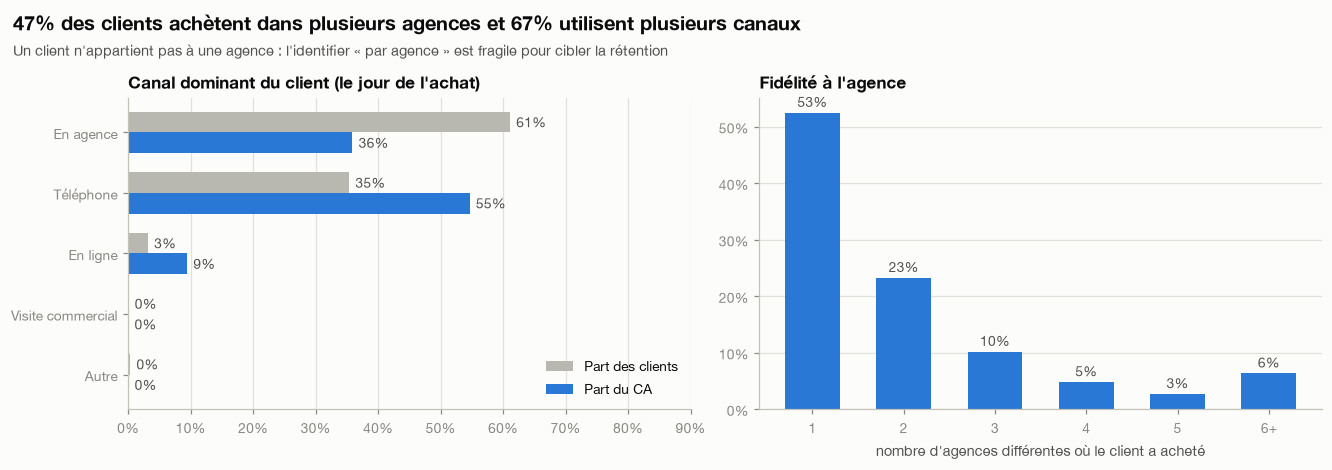

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
dom = cl.groupby("channel").agg(clients=("client_id", "count"), ca=("rev_pos", "sum")).loc[order]
y = np.arange(len(order))[::-1]
h = 0.34
axes[0].barh(y + h / 2, dom["clients"] / dom["clients"].sum(), height=h, color=NEUTRAL, label="Part des clients")
axes[0].barh(y - h / 2, dom["ca"] / dom["ca"].sum(), height=h, color=C["blue"], label="Part du CA")
for yi, a, b_ in zip(y, dom["clients"] / dom["clients"].sum(), dom["ca"] / dom["ca"].sum()):
    axes[0].text(a + 0.01, yi + h / 2, f"{a:.0%}", va="center", fontsize=9, color=INK2)
    axes[0].text(b_ + 0.01, yi - h / 2, f"{b_:.0%}", va="center", fontsize=9, color=INK2)
axes[0].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[0], "x")
axes[0].set_xlim(0, 0.9)
axes[0].grid(axis="x")
axes[0].grid(axis="y", visible=False)
axes[0].legend(loc="lower right")
axes[0].set_title("Canal dominant du client (le jour de l'achat)")
nb_br = cl["n_branch"].clip(upper=6).value_counts(normalize=True).sort_index()
axes[1].bar(nb_br.index, nb_br.values, width=0.6, color=C["blue"])
for x, v in nb_br.items():
    axes[1].text(x, v + 0.01, f"{v:.0%}", ha="center", fontsize=9, color=INK2)
axes[1].set_xticks(nb_br.index, [str(i) if i < 6 else "6+" for i in nb_br.index])
axes[1].set_xlabel("nombre d'agences différentes où le client a acheté")
pct_axis(axes[1])
axes[1].set_title("Fidélité à l'agence")
multi_ch = (cl["n_channel"] > 1).mean()
multi_br = (cl["n_branch"] > 1).mean()
headline(fig, f"{multi_br:.0%} des clients achètent dans plusieurs agences et {multi_ch:.0%} utilisent plusieurs canaux",
         "Un client n'appartient pas à une agence : l'identifier « par agence » est fragile pour cibler la rétention")
plt.show()

## 4. Rythme d'achat → comment définir un client « perdu » ?

**Question Q4 — la plus structurante du modèle.** Il n'y a pas de colonne « churn » : le contexte B2B est **non contractuel** (le client ne résilie pas, il cesse simplement d'acheter). On doit *inventer* la définition à partir du rythme d'achat observé. Trois pièges : (1) un seuil trop court étiquette « perdus » des clients qui reviendraient, (2) un seuil trop long donne des alertes trop tardives pour agir, (3) un seuil unique ignore que chaque client a son propre rythme.

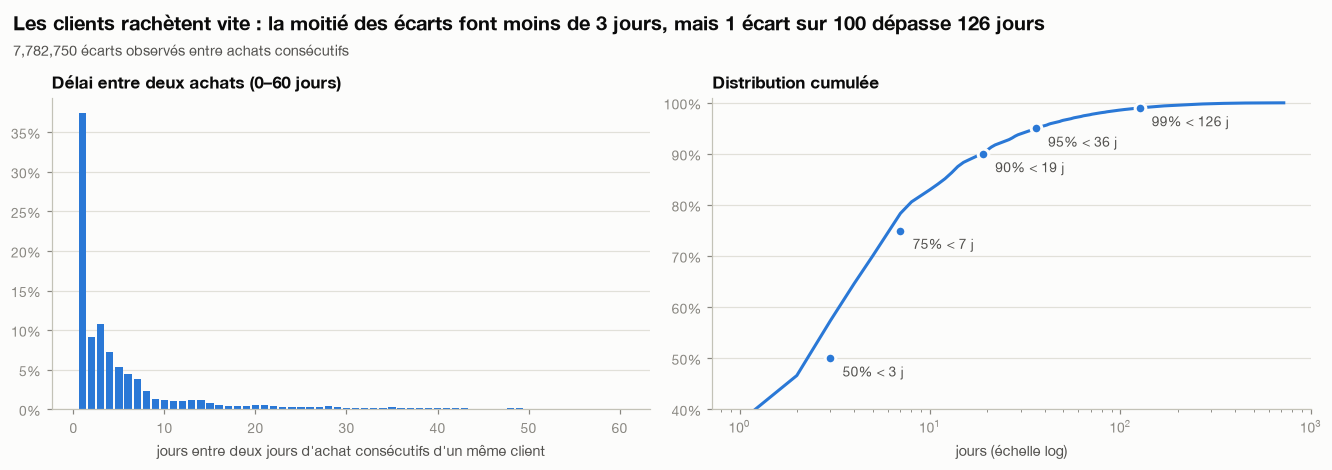

In [16]:
gaps = q("""
WITH g AS (SELECT d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap FROM bd)
SELECT gap, count(*) AS n FROM g WHERE gap IS NOT NULL GROUP BY 1 ORDER BY 1""")
gaps["cdf"] = gaps["n"].cumsum() / gaps["n"].sum()
gq = {p: int(gaps.loc[gaps["cdf"] >= p, "gap"].iloc[0]) for p in (0.5, 0.75, 0.9, 0.95, 0.99)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
g60 = gaps[gaps["gap"] <= 60]
axes[0].bar(g60["gap"], g60["n"] / gaps["n"].sum(), width=0.8, color=C["blue"])
pct_axis(axes[0])
axes[0].set_xlabel("jours entre deux jours d'achat consécutifs d'un même client")
axes[0].set_title("Délai entre deux achats (0–60 jours)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(gaps["gap"], gaps["cdf"], color=C["blue"])
axes[1].set_xscale("log")
for p, d in gq.items():
    axes[1].plot([d], [p], "o", color=C["blue"], ms=7, mec=SURF, mew=2)
    axes[1].annotate(f"{p:.0%} < {d} j", (d, p), xytext=(8, -12), textcoords="offset points", fontsize=9, color=INK2)
pct_axis(axes[1])
axes[1].set_ylim(0.4, 1.01)
axes[1].set_xlabel("jours (échelle log)")
axes[1].set_title("Distribution cumulée")
headline(fig, f"Les clients rachètent vite : la moitié des écarts font moins de {gq[0.5]} jours, mais 1 écart sur 100 dépasse {gq[0.99]} jours",
         f"{gaps['n'].sum():,.0f} écarts observés entre achats consécutifs")
plt.show()

La grande majorité des écarts est courte (**médiane 3 jours, 90 % sous 19 jours, 95 % sous ~5 semaines**), mais la **queue est lourde** : 1 % des écarts dépasse 4 mois. Un seuil de churn inférieur à ~4 mois étiquettera à tort comme « perdus » une partie de clients qui reviennent. Mais ces écarts mélangent des clients qui achètent chaque semaine et des clients qui achètent 4 fois par an. Séparons-les :

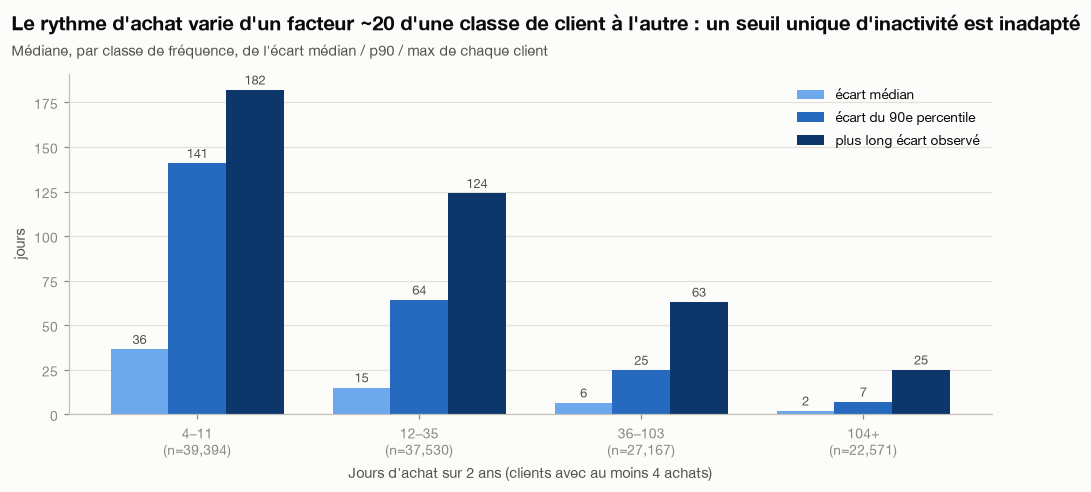

In [17]:
pc = q("""
WITH g AS (SELECT client_id, d, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap FROM bd)
SELECT client_id, median(gap) AS med_gap, quantile_cont(gap, 0.9) AS p90_gap, max(gap) AS max_gap
FROM g WHERE gap IS NOT NULL GROUP BY 1""").merge(cl[["client_id", "n_days", "freq_class"]], on="client_id")
pc = pc[pc["n_days"] >= 4]
tab = pc.groupby("freq_class", observed=True).agg(clients=("client_id", "count"), med_gap=("med_gap", "median"), p90_gap=("p90_gap", "median"), max_gap=("max_gap", "median"))

fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
x = np.arange(len(tab))
w = 0.26
ax.bar(x - w, tab["med_gap"], width=w, color=SEQ[2], label="écart médian")
ax.bar(x, tab["p90_gap"], width=w, color=SEQ[4], label="écart du 90e percentile")
ax.bar(x + w, tab["max_gap"], width=w, color=SEQ[6], label="plus long écart observé")
for xi, (a, b_, c_) in enumerate(zip(tab["med_gap"], tab["p90_gap"], tab["max_gap"])):
    for off, v in zip((-w, 0, w), (a, b_, c_)):
        ax.text(xi + off, v + 3, f"{v:.0f}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, [f"{i}\n(n={n_:,.0f})" for i, n_ in zip(tab.index, tab["clients"])])
ax.set_xlabel("Jours d'achat sur 2 ans (clients avec au moins 4 achats)")
ax.set_ylabel("jours")
ax.legend(loc="upper right")
headline(fig, "Le rythme d'achat varie d'un facteur ~20 d'une classe de client à l'autre : un seuil unique d'inactivité est inadapté",
         "Médiane, par classe de fréquence, de l'écart médian / p90 / max de chaque client")
plt.show()

Un silence de 60 jours est **un signal d'alarme fort** pour un client qui achète toutes les semaines (écart p90 : 7 jours), et un **non-événement** pour un client à 4-11 achats sur 2 ans (écart médian : 36 jours). Cela plaide pour des features **relatives au rythme du client** (récence ÷ écart habituel) plutôt qu'une récence brute, et pour une évaluation du modèle **par segment de fréquence**.

### Courbe de retour : quand un silence devient-il définitif ?
On prend 7 photos (du 22/09/2023 au 22/03/2024), et pour chaque client actif dans l'année précédente on regarde, **selon son temps de silence**, la probabilité qu'il n'achète plus du tout dans les 180 jours suivants.

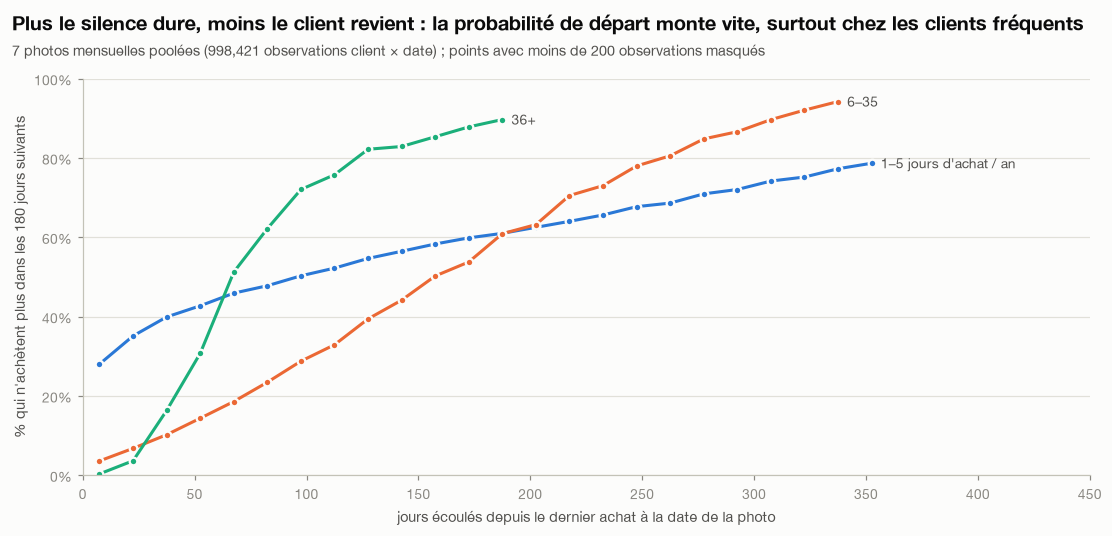

In [18]:
def light_snap(T: str) -> pd.DataFrame:
    """One row per client active in the 365 days before T, with recency and days until next purchase (NaN if none)."""
    return q(f"""
    WITH a AS (
        SELECT client_id, max(d) AS last_d,
               count(*) FILTER (WHERE d >= DATE '{T}' - 365) AS f365,
               sum(rev_pos) FILTER (WHERE d >= DATE '{T}' - 365) AS rev365,
               sum(rev_pos) FILTER (WHERE d >= DATE '{T}' - 180) AS rev180
        FROM bd WHERE d < DATE '{T}' GROUP BY 1),
    f AS (SELECT client_id, min(d) AS next_d FROM bd WHERE d >= DATE '{T}' GROUP BY 1)
    SELECT a.client_id, date_diff('day', a.last_d, DATE '{T}') AS recency, a.f365, a.rev365, a.rev180,
           date_diff('day', DATE '{T}', f.next_d) AS days_to_next
    FROM a LEFT JOIN f USING (client_id) WHERE a.f365 > 0""")


def is_churn(df, horizon):
    """No purchase in [T, T+horizon)."""
    return df["days_to_next"].isna() | (df["days_to_next"] >= horizon)


SNAPS_POOL = ["2023-09-22", "2023-10-22", "2023-11-22", "2023-12-22", "2024-01-22", "2024-02-22", "2024-03-22"]
pool = pd.concat([light_snap(t).assign(T=t) for t in SNAPS_POOL], ignore_index=True)
pool["churn"] = is_churn(pool, 180)
FREQ_BINS = [0, 5, 35, np.inf]
FREQ_LABELS = ["1–5 jours d'achat / an", "6–35", "36+"]
pool["freq_class"] = pd.cut(pool["f365"], FREQ_BINS, labels=FREQ_LABELS)
pool["rec_bin"] = (pool["recency"] // 15 * 15).clip(upper=345)
curve = pool.groupby(["freq_class", "rec_bin"], observed=True)["churn"].agg(["mean", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
for lab, colr in zip(FREQ_LABELS, [C["blue"], C["orange"], C["aqua"]]):
    d = curve[(curve["freq_class"] == lab) & (curve["count"] >= 200)]
    ax.plot(d["rec_bin"] + 7.5, d["mean"], color=colr, marker="o", ms=5, mec=SURF, mew=1.5)
    label_end(ax, d["rec_bin"].iloc[-1] + 7.5, d["mean"].iloc[-1], lab)
pct_axis(ax)
ax.set_ylim(0, 1)
ax.set_xlim(0, 450)
ax.set_xlabel("jours écoulés depuis le dernier achat à la date de la photo")
ax.set_ylabel("% qui n'achètent plus dans les 180 jours suivants")
headline(fig, "Plus le silence dure, moins le client revient : la probabilité de départ monte vite, surtout chez les clients fréquents",
         f"7 photos mensuelles poolées ({len(pool):,.0f} observations client × date) ; points avec moins de 200 observations masqués")
plt.show()

**Lecture** :
- Un client **fréquent (36+ jours d'achat/an)** passe de ~0 % à **~50 % de probabilité de départ en à peine 60-70 jours de silence**, et à ~70 % à 100 jours : c'est la zone d'**alerte précoce** exploitable (et c'est là que se trouve la valeur).
- Le client occasionnel (1-5 jours/an) a déjà ~30 % de risque dès son dernier achat (beaucoup d'achats uniques), et le risque ne grimpe ensuite que lentement : le silence est peu informatif pour lui.
- Les courbes sont **continues** : il n'existe pas de seuil naturel net, la définition de churn est un **choix business** (arbitrage entre précocité de l'alerte et fiabilité du label).

### Sensibilité de la définition (base suivie × horizon)
Taux de churn (clients, à gauche) et part du CA des churners (à droite) selon la fenêtre de la population suivie et l'horizon sans achat, photo du 22/12/2023.

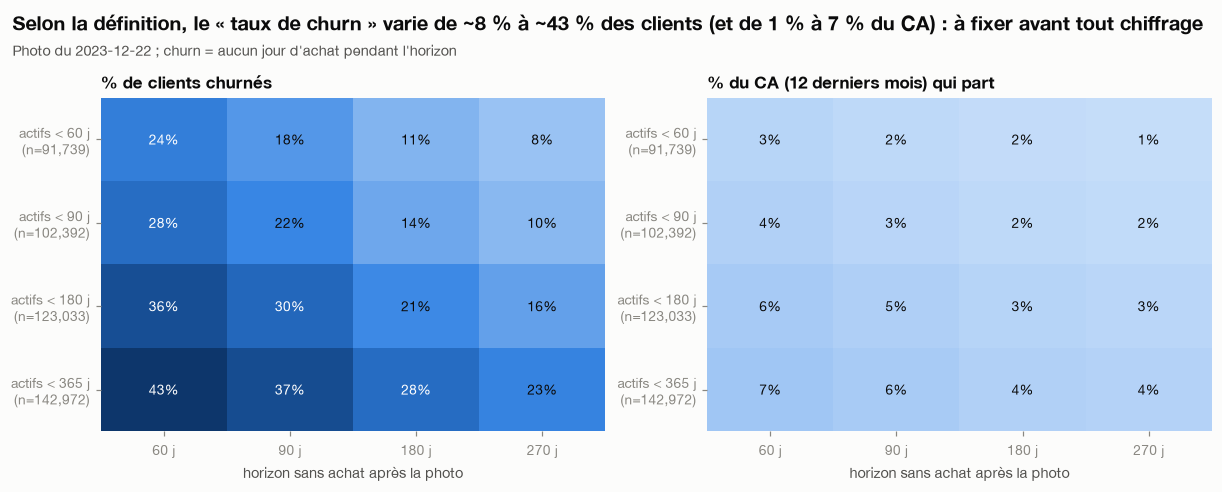

In [19]:
T_GRID = "2023-12-22"
g = light_snap(T_GRID)
BASES = [60, 90, 180, 365]
HORIZONS = [60, 90, 180, 270]
r_cnt = pd.DataFrame({h_: [is_churn(g[g["recency"] <= b_], h_).mean() for b_ in BASES] for h_ in HORIZONS}, index=BASES)
r_rev = pd.DataFrame({h_: [(g[g["recency"] <= b_]["rev365"] * is_churn(g[g["recency"] <= b_], h_)).sum() / g[g["recency"] <= b_]["rev365"].sum() for b_ in BASES] for h_ in HORIZONS}, index=BASES)
r_n = pd.Series({b_: int((g["recency"] <= b_).sum()) for b_ in BASES})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
vmax = r_cnt.to_numpy().max()
heat(axes[0], r_cnt, "% de clients churnés", vmax=vmax)
heat(axes[1], r_rev, "% du CA (12 derniers mois) qui part", vmax=vmax)
for ax_ in axes:
    ax_.set_yticks(range(len(BASES)), [f"actifs < {b_} j\n(n={r_n[b_]:,.0f})" for b_ in BASES])
    ax_.set_xticks(range(len(HORIZONS)), [f"{h_} j" for h_ in HORIZONS])
    ax_.set_xlabel("horizon sans achat après la photo")
headline(fig, "Selon la définition, le « taux de churn » varie de ~8 % à ~43 % des clients (et de 1 % à 7 % du CA) : à fixer avant tout chiffrage",
         f"Photo du {T_GRID} ; churn = aucun jour d'achat pendant l'horizon")
plt.show()

**Ce que dit ce tableau** : quelle que soit la définition, le **CA concerné est 5 à 8 fois plus faible que la part de clients** : les clients qui partent sont des **petits clients**. Et plus on suit large (base 365 jours) ou court (horizon 60 j), plus on inclut des clients déjà quasi partis ou simplement en pause, ce qui gonfle artificiellement le churn.

**Définition retenue pour la suite** (modifiable en haut du notebook) : *population = clients ayant acheté dans les 180 derniers jours ; churné = aucun achat pendant les 180 jours suivants.* Compromis : assez court pour laisser le temps d'agir (alerte avec un horizon de 6 mois), assez long pour dépasser les 99 % des écarts « normaux » (4 mois) et les creux saisonniers.

## 5. Combien de churn, et combien de CA en jeu ?

**Question Q5.** On construit la « photo » principale à `T_SNAP` : une ligne par client actif avec ses caractéristiques passées (récence, fréquence, panier, tendance, retours, délai de facturation…) et son statut futur.

In [20]:
con.execute(f"""
CREATE OR REPLACE TABLE feat AS
WITH win AS (
    SELECT *, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
    FROM bd WHERE d < DATE '{T_SNAP}' AND d >= DATE '{T_SNAP}' - 365),
agg AS (
    SELECT client_id, count(*) AS f365, sum(rev_pos) AS rev365, max(d) AS last_d,
           median(gap) AS med_gap, quantile_cont(gap, 0.9) AS p90_gap,
           count(*) FILTER (WHERE d >= DATE '{T_SNAP}' - 90) AS f90,
           count(*) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180) AS f90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 90), 0) AS rev90,
           coalesce(sum(rev_pos) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180), 0) AS rev90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 180), 0) AS rev180,
           -sum(rev_neg) / nullif(sum(rev_pos), 0) AS ret_share,
           avg(lag_mean) AS lag_mean, sum(n_prod) / count(*) AS basket_breadth,
           count(DISTINCT branch_id) AS n_branch, mode(channel) AS channel, mode(branch_id) AS home_branch
    FROM win GROUP BY 1),
fut AS (
    SELECT client_id, count(*) AS n_fut, sum(rev_pos) AS rev_fut
    FROM bd WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + {HORIZON} GROUP BY 1)
SELECT a.*, date_diff('day', a.last_d, DATE '{T_SNAP}') AS recency,
       coalesce(f.n_fut, 0) AS n_fut, coalesce(f.rev_fut, 0) AS rev_fut, coalesce(f.n_fut, 0) = 0 AS churn
FROM agg a LEFT JOIN fut f USING (client_id)""")
Fall = q("SELECT * FROM feat")
F = Fall[Fall["recency"] <= BASE_DAYS].copy()
F["freq_class"] = pd.cut(F["f365"], FREQ_BINS, labels=FREQ_LABELS)
F["avg_basket"] = F["rev365"] / F["f365"]
n_base = len(F)
churn_rate = F["churn"].mean()
rev_share = (F["rev365"] * F["churn"]).sum() / F["rev365"].sum()
print(f"Photo du {T_SNAP} · base = clients actifs < {BASE_DAYS} j : {n_base:,.0f} clients · churn à {HORIZON} j = {churn_rate:.1%} des clients "
      f"= {rev_share:.1%} du CA des 12 derniers mois de la base ({(F['rev365'] * F['churn']).sum() / 1e6:,.0f} M sur {F['rev365'].sum() / 1e6:,.0f} M)")

Photo du 2024-03-22 · base = clients actifs < 180 j : 120,114 clients · churn à 180 j = 18.3% des clients = 3.1% du CA des 12 derniers mois de la base (148 M sur 4,824 M)


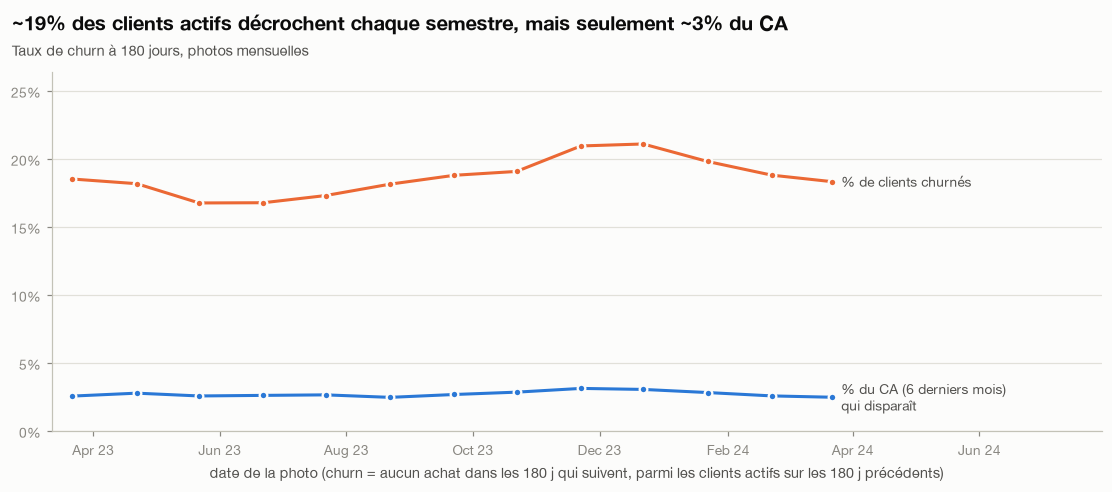

In [21]:
SNAPS_TS = [str(d.date()) for d in pd.date_range("2023-03-22", "2024-03-22", freq=pd.DateOffset(months=1))]
rows = []
for t in SNAPS_TS:
    g_ = light_snap(t)
    g_ = g_[g_["recency"] <= 180]
    c_ = is_churn(g_, 180)
    rows.append(dict(T=pd.Timestamp(t), clients=c_.mean(), ca=(g_["rev180"] * c_).sum() / g_["rev180"].sum()))
ts = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(ts["T"], ts["clients"], color=C["orange"], marker="o", ms=5, mec=SURF, mew=1.5)
ax.plot(ts["T"], ts["ca"], color=C["blue"], marker="o", ms=5, mec=SURF, mew=1.5)
label_end(ax, ts["T"].iloc[-1], ts["clients"].iloc[-1], "% de clients churnés")
label_end(ax, ts["T"].iloc[-1], ts["ca"].iloc[-1], "% du CA (6 derniers mois)\nqui disparaît")
pct_axis(ax)
ax.set_ylim(0, ts["clients"].max() * 1.25)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(ts["T"].iloc[0] - pd.Timedelta(days=10), ts["T"].iloc[-1] + pd.Timedelta(days=130))
ax.set_xlabel("date de la photo (churn = aucun achat dans les 180 j qui suivent, parmi les clients actifs sur les 180 j précédents)")
headline(fig, f"~{ts['clients'].mean():.0%} des clients actifs décrochent chaque semestre, mais seulement ~{ts['ca'].mean():.0%} du CA",
         "Taux de churn à 180 jours, photos mensuelles")
plt.show()

Le churn en nombre de clients est **stable dans le temps** (17 % à 21 %, léger pic sur les photos de décembre) ; le **CA concerné est ~7 fois plus faible** (2,5 % à 3,2 %). Un modèle devra donc être évalué **en valeur** et pas seulement en nombre de clients.

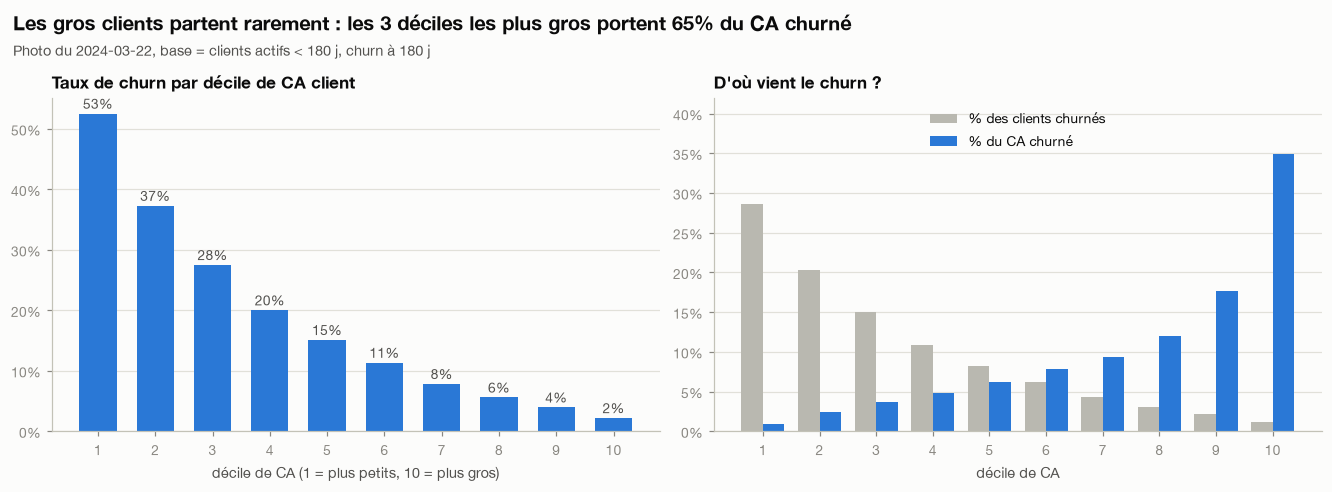

,clients,taux_churn,ca_12m,ca_moyen
rev_decile,,,,
1,"12,012.000",0.525,"2,813,171.637",234.197
2,"12,011.000",0.373,"9,689,045.557",806.681
3,"12,011.000",0.275,"20,195,690.832","1,681.433"
4,"12,012.000",0.200,"36,161,322.224","3,010.433"
5,"12,011.000",0.151,"61,683,237.720","5,135.562"
6,"12,011.000",0.113,"103,974,860.537","8,656.636"
7,"12,012.000",0.078,"178,773,151.712","14,882.880"
8,"12,011.000",0.056,"325,827,155.163","27,127.396"
9,"12,011.000",0.040,"682,426,737.467","56,816.813"


In [22]:
F["rev_decile"] = pd.qcut(F["rev365"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
dec = F.groupby("rev_decile").apply(lambda g_: pd.Series(dict(
    churn=g_["churn"].mean(), rev=g_["rev365"].sum(), rev_churn=(g_["rev365"] * g_["churn"]).sum(), n=len(g_), n_churn=g_["churn"].sum())), include_groups=False)
dec["share_rev_churn"] = dec["rev_churn"] / dec["rev_churn"].sum()
dec["share_n_churn"] = dec["n_churn"] / dec["n_churn"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axes[0].bar(dec.index, dec["churn"], width=0.65, color=C["blue"])
for x, v in dec["churn"].items():
    axes[0].text(x, v + 0.008, f"{v:.0%}", ha="center", fontsize=9, color=INK2)
pct_axis(axes[0])
axes[0].set_title("Taux de churn par décile de CA client")
axes[0].set_xlabel("décile de CA (1 = plus petits, 10 = plus gros)")
axes[0].set_xticks(range(1, 11))
w = 0.38
axes[1].bar(dec.index - w / 2, dec["share_n_churn"], width=w, color=NEUTRAL, label="% des clients churnés")
axes[1].bar(dec.index + w / 2, dec["share_rev_churn"], width=w, color=C["blue"], label="% du CA churné")
pct_axis(axes[1])
axes[1].set_title("D'où vient le churn ?")
axes[1].set_xlabel("décile de CA")
axes[1].set_xticks(range(1, 11))
axes[1].set_ylim(0, 0.42)
axes[1].legend(loc="upper center")
top3 = dec.loc[8:10, "share_rev_churn"].sum()
headline(fig, f"Les gros clients partent rarement : les 3 déciles les plus gros portent {top3:.0%} du CA churné",
         f"Photo du {T_SNAP}, base = clients actifs < {BASE_DAYS} j, churn à {HORIZON} j")
plt.show()
dec[["n", "churn", "rev"]].assign(ca_moyen=lambda d_: d_["rev"] / d_["n"]).rename(columns={"n": "clients", "churn": "taux_churn", "rev": "ca_12m"})

Le churn **en nombre** vient des petits clients (taux élevé), mais le **CA churné** se partage : les petits clients ont un taux de churn élevé pour très peu d'euros, les gros clients un faible taux de churn mais des montants unitaires élevés. Un client du dernier décile pèse en moyenne ~1 000 fois un client du premier (283 k vs 0,2 k de CA annuel) : **la valeur à protéger est dans le haut de la distribution**, là où l'action commerciale (téléphone, visite) est justifiée économiquement et où le client a un interlocuteur dédié.

### Pont de CA : perte pure ou simple volatilité ?
Entre les 180 jours avant et les 180 jours après la photo, d'où vient la variation de CA des clients ? La **perte totale** (client parti) n'est qu'une partie : un client peut aussi **réduire** ses achats sans jamais « partir ». On sépare les deux, en gardant en tête que le CA d'un client fluctue naturellement d'une période à l'autre.

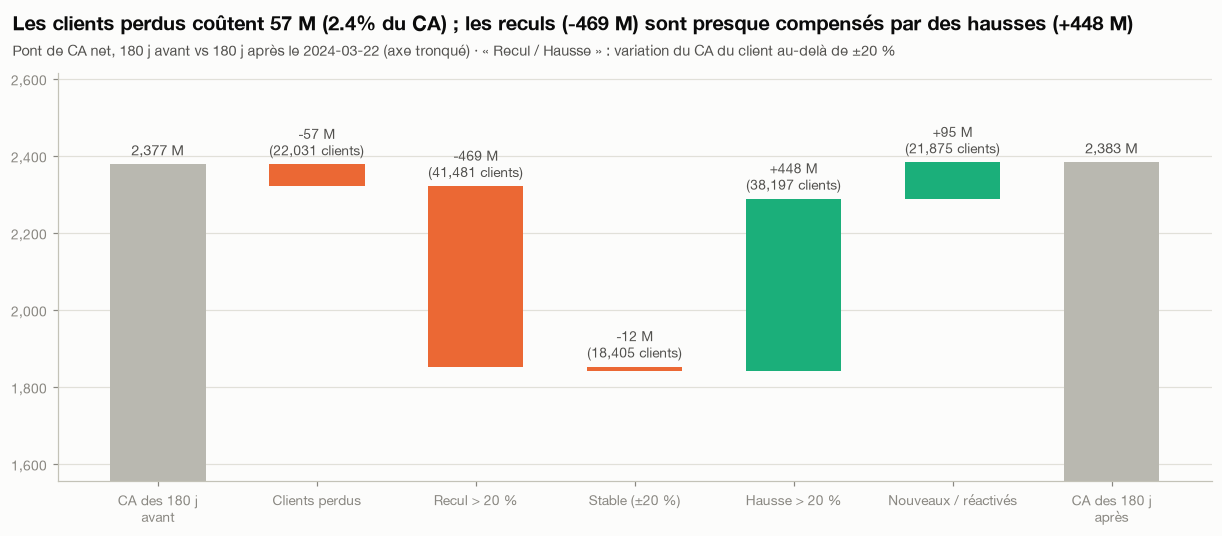

In [23]:
bridge = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_SNAP}' - 180 AND d < DATE '{T_SNAP}'), 0) AS prev_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 180 AND d < DATE '{T_SNAP}'), 0) AS prev_pos,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + 180), 0) AS next_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + 180), 0) AS next_pos
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE prev_pos > 0 OR next_pos > 0""")
bridge["bucket"] = np.select(
    [bridge.prev_pos == 0, bridge.next_pos == 0, bridge.next_net < 0.8 * bridge.prev_net, bridge.next_net > 1.2 * bridge.prev_net],
    ["Nouveaux / réactivés", "Clients perdus", "Recul > 20 %", "Hausse > 20 %"], default="Stable (±20 %)")
bridge["delta"] = bridge["next_net"] - bridge["prev_net"]
wf = bridge.groupby("bucket").agg(delta=("delta", "sum"), n=("client_id", "count"))
steps = ["Clients perdus", "Recul > 20 %", "Stable (±20 %)", "Hausse > 20 %", "Nouveaux / réactivés"]
start, end = bridge["prev_net"].sum(), bridge["next_net"].sum()
cums = start + wf.loc[steps, "delta"].cumsum()

fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
ax.bar(0, start, width=0.6, color=NEUTRAL)
ax.text(0, start + start * 0.01, f"{start / 1e6:,.0f} M", ha="center", fontsize=9.5, color=INK2)
cum = start
for i, st in enumerate(steps, start=1):
    dlt = wf.loc[st, "delta"]
    ax.bar(i, dlt, bottom=cum, width=0.6, color=C["orange"] if dlt < 0 else C["aqua"])
    ax.text(i, max(cum, cum + dlt) + start * 0.01, f"{dlt / 1e6:+,.0f} M\n({wf.loc[st, 'n']:,.0f} clients)", ha="center", fontsize=9, color=INK2)
    cum += dlt
ax.bar(len(steps) + 1, end, width=0.6, color=NEUTRAL)
ax.text(len(steps) + 1, end + start * 0.01, f"{end / 1e6:,.0f} M", ha="center", fontsize=9.5, color=INK2)
ax.set_xticks(range(len(steps) + 2), ["CA des 180 j\navant", *steps, "CA des 180 j\naprès"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
ax.set_ylim(min(cums.min(), end) - 0.12 * start, start * 1.1)
ax.grid(axis="x", visible=False)
lost, decline, growth = wf.loc["Clients perdus", "delta"], wf.loc["Recul > 20 %", "delta"], wf.loc["Hausse > 20 %", "delta"]
share_lost_6m = abs(lost) / start
headline(fig, f"Les clients perdus coûtent {abs(lost) / 1e6:,.0f} M ({share_lost_6m:.1%} du CA) ; les reculs ({decline / 1e6:,.0f} M) sont presque compensés par des hausses ({growth / 1e6:+,.0f} M)",
         f"Pont de CA net, 180 j avant vs 180 j après le {T_SNAP} (axe tronqué) · « Recul / Hausse » : variation du CA du client au-delà de ±20 %")
plt.show()

Le **CA bouge énormément client par client** (≈ 20 % du CA recule, ≈ 19 % progresse, chaque semestre), mais ces mouvements **se compensent presque exactement** : l'essentiel est de la **volatilité normale** des achats B2B (chantiers qui démarrent ou finissent, effets de commande groupée), pas de l'érosion. Seule la **perte pure** (clients qui disparaissent) n'est pas compensée à l'identique — et elle est en partie remplacée par les **nouveaux/réactivés**.

Un « recul » est-il au moins **durable** ? On le teste : parmi les clients dont le CA a chuté de plus de 50 % entre les semestres A et B, quelle part n'a toujours pas rebondi au semestre C, comparé à des clients stables ?

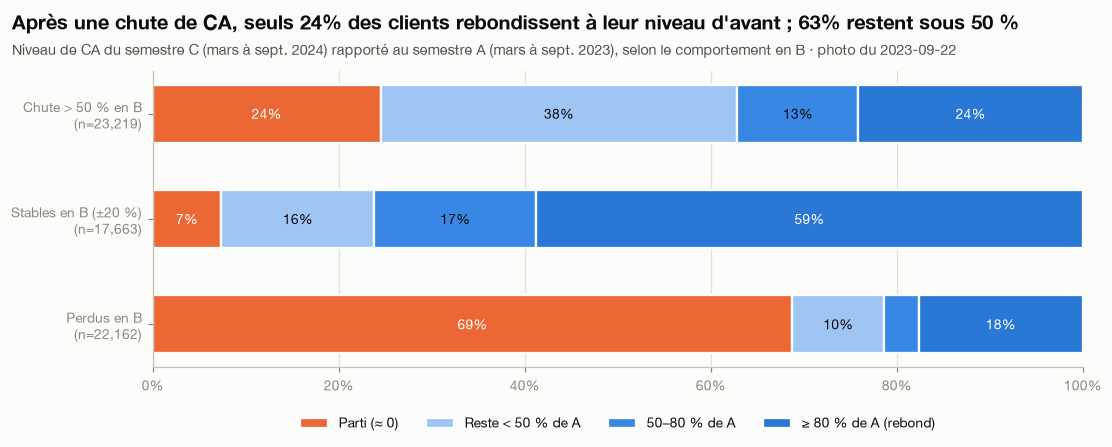

In [24]:
T_P = "2023-09-22"
pers = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' - 180 AND d < DATE '{T_P}'), 0) AS a,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' AND d < DATE '{T_P}' + 180), 0) AS b,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' + 180 AND d < DATE '{T_P}' + 360), 0) AS c
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE a > 0""")
grp_drop = pers[(pers["b"] > 0) & (pers["b"] < 0.5 * pers["a"])]
grp_stable = pers[(pers["b"] >= 0.8 * pers["a"]) & (pers["b"] <= 1.2 * pers["a"])]
grp_lost = pers[pers["b"] <= 0]
cats = ["Parti (≈ 0)", "Reste < 50 % de A", "50–80 % de A", "≥ 80 % de A (rebond)"]


def dist(g_):
    r = g_["c"] / g_["a"]
    return pd.Series([(r <= 0.02).mean(), ((r > 0.02) & (r < 0.5)).mean(), ((r >= 0.5) & (r < 0.8)).mean(), (r >= 0.8).mean()], index=cats)


pdist = pd.DataFrame({f"Chute > 50 % en B\n(n={len(grp_drop):,.0f})": dist(grp_drop), f"Stables en B (±20 %)\n(n={len(grp_stable):,.0f})": dist(grp_stable), f"Perdus en B\n(n={len(grp_lost):,.0f})": dist(grp_lost)}).T
fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
left = np.zeros(len(pdist))
y = np.arange(len(pdist))[::-1]
for col, colr in zip(cats, [C["orange"], SEQ[1], SEQ[3], C["blue"]]):
    ax.barh(y, pdist[col], left=left, color=colr, height=0.55, label=col, edgecolor=SURF, linewidth=1.5)
    for yi, l, v in zip(y, left, pdist[col]):
        if v > 0.06:
            ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if colr in (C["orange"], C["blue"]) else INK)
    left += pdist[col].to_numpy()
ax.set_yticks(y, pdist.index)
pct_axis(ax, "x")
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
headline(fig, f"Après une chute de CA, seuls {pdist.iloc[0, 3]:.0%} des clients rebondissent à leur niveau d'avant ; {pdist.iloc[0, 0] + pdist.iloc[0, 1]:.0%} restent sous 50 %",
         f"Niveau de CA du semestre C (mars à sept. 2024) rapporté au semestre A (mars à sept. 2023), selon le comportement en B · photo du {T_P}")
plt.show()

Un **recul > 50 % est persistant** pour la majorité des clients concernés : ce n'est donc pas que du bruit, c'est un **signal précoce de départ progressif** (le client réduit son périmètre, partage ses achats avec un concurrent, avant de parfois disparaître). Cela ouvre un 2e label possible — *« chute durable de CA »* — en complément du churn total, et à tester au moment de la modélisation.

### Confrontation aux hypothèses du chiffrage d'équipe
`ClientCo_priorisation_use_cases-2.xlsx` suppose que **5 / 8 / 12 %** du CA part chaque année avec les clients perdus, puis 50 % détectés à temps, 20 % retenus, 24,65 % de marge brute : ≈ **30,6 M de marge** en régime de croisière (central). On mesure ici la 1re hypothèse sur ce dataset, de deux manières :
- **12 mois avant / 12 mois après** le 22/09/2023 : CA des clients sans aucun achat l'année suivante (borne basse : les clients qui reviennent entre-temps ne comptent pas).
- **Semestre, annualisé (×2)** : borne haute (certains « perdus » à 6 mois reviennent avant 12 mois).

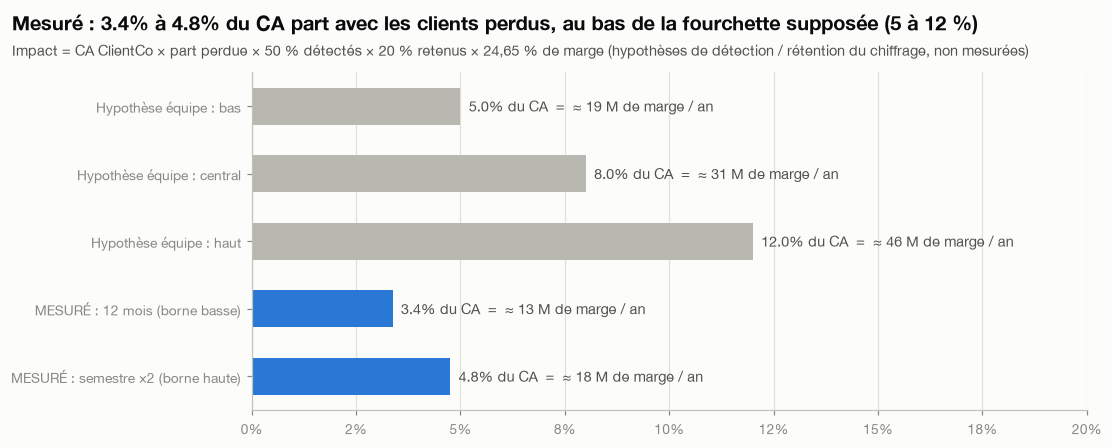

19.9% des clients actifs l'année précédente n'achètent plus du tout l'année suivante, pour 3.4% du CA.


In [25]:
T12 = "2023-09-22"
b12 = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T12}' - 365 AND d < DATE '{T12}'), 0) AS prev_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T12}' - 365 AND d < DATE '{T12}'), 0) AS prev_pos,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T12}' AND d < DATE '{T12}' + 365), 0) AS next_pos
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE prev_pos > 0""")
share_lost = b12.loc[b12["next_pos"] == 0, "prev_net"].sum() / b12["prev_net"].sum()
n_lost12 = (b12["next_pos"] == 0).mean()
share_lost_6m_ann = 2 * share_lost_6m

CA_COMPANY = 15504.0  # M, implicit in the team's xlsx (124.03 M saved = CA x 8 % x 50 % x 20 %)
MARGIN, DETECT, RETAIN = 0.2465, 0.5, 0.2


def impact(share):
    return CA_COMPANY * share * DETECT * RETAIN * MARGIN


scen = pd.DataFrame({"share": [0.05, 0.08, 0.12, share_lost, share_lost_6m_ann]},
                    index=["Hypothèse équipe : bas", "Hypothèse équipe : central", "Hypothèse équipe : haut",
                           "MESURÉ : 12 mois (borne basse)", "MESURÉ : semestre ×2 (borne haute)"])
scen["impact"] = scen["share"].map(impact)

fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
y = np.arange(len(scen))[::-1]
ax.barh(y, scen["share"], color=[NEUTRAL] * 3 + [C["blue"]] * 2, height=0.55)
for yi, v, imp in zip(y, scen["share"], scen["impact"]):
    ax.text(v + 0.002, yi, f"{v:.1%} du CA  =  ≈ {imp:,.0f} M de marge / an", va="center", fontsize=9.5, color=INK2)
ax.set_yticks(y, scen.index)
pct_axis(ax, "x")
ax.set_xlim(0, 0.2)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
headline(fig, f"Mesuré : {share_lost:.1%} à {share_lost_6m_ann:.1%} du CA part avec les clients perdus, au bas de la fourchette supposée (5 à 12 %)",
         "Impact = CA ClientCo × part perdue × 50 % détectés × 20 % retenus × 24,65 % de marge (hypothèses de détection / rétention du chiffrage, non mesurées)")
plt.show()
print(f"{n_lost12:.1%} des clients actifs l'année précédente n'achètent plus du tout l'année suivante, pour {share_lost:.1%} du CA.")

**À reporter dans le chiffrage d'équipe** (la ligne « Part du CA perdue chaque année » est marquée « hypothèse à mesurer sur le dataset ») :
- La mesure donne **~3,4 à 4,8 %** : le scénario **bas** (5 %) est le plus réaliste, le central (8 %) paraît **optimiste d'un facteur ~2**. À hypothèses de détection / rétention inchangées, l'impact du churn pur serait de l'ordre de **13 à 18 M de marge / an** au lieu de 30,6 M.
- **Deux réserves** vont dans des sens opposés : (a) un client « perdu » ici peut simplement avoir acheté dans une **agence hors périmètre** du dataset (« subset of stores »), ce qui surestime le churn ; (b) la **chute durable de CA** (clients qui réduisent sans partir) n'est pas dans ce chiffre et peut doubler l'enjeu — c'est un angle à creuser.
- Les taux de détection (50 %) et de rétention (20 %) restent des **hypothèses sans mesure** : un pilote avec groupe témoin est indispensable (« clear success measurement » demandé par la Commercial Director ; « get the Head of Sales onboard » selon OffSupp).

## 6. Les nouveaux clients restent-ils ? (cohortes)

**Question Q6.** Le jeu de données démarre au 22/09/2022 : tous les clients déjà existants apparaissent « nouveaux » en septembre-octobre 2022 (*left-censoring*). Pour identifier de vrais nouveaux clients, on impose une **période de chauffe de 3 mois** (premier achat à partir du 22/12/2022) : le 99e percentile des écarts d'achat est de ~4 mois, quelques « nouveaux » sont donc en réalité des clients dormants qui reviennent.

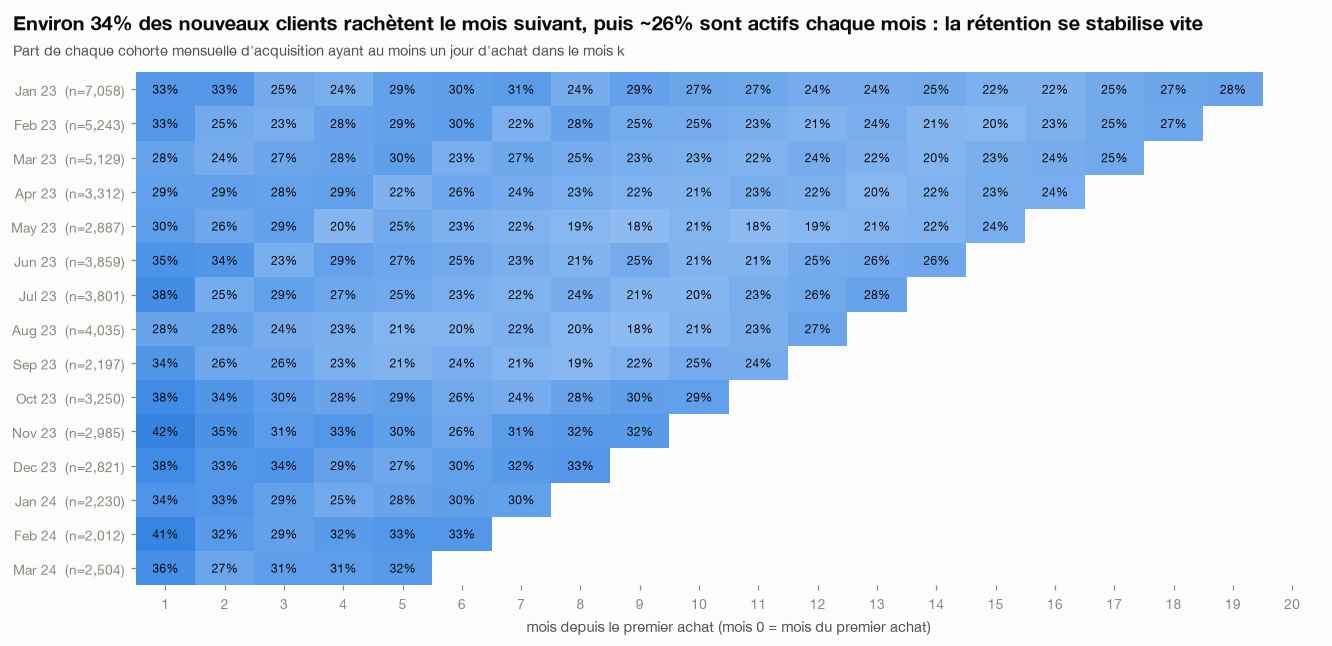

In [26]:
coh = q("""
WITH f AS (SELECT client_id, min(d) AS first_d FROM bd GROUP BY 1),
c AS (SELECT client_id, date_trunc('month', first_d) AS coh FROM f WHERE first_d >= DATE '2023-01-01' AND first_d < DATE '2024-04-01'),
act AS (SELECT DISTINCT client_id, date_trunc('month', d) AS m FROM bd)
SELECT c.coh, date_diff('month', c.coh, act.m) AS k, count(*) AS n FROM c JOIN act USING (client_id) GROUP BY 1, 2""")
mat = coh.pivot(index="coh", columns="k", values="n")
ret = mat.div(mat[0], axis=0)
last_full = pd.Timestamp("2024-08-01")
for coh_date in ret.index:
    for k in ret.columns:
        if coh_date + pd.DateOffset(months=int(k)) > last_full:
            ret.loc[coh_date, k] = np.nan
ret = ret.iloc[:, 1:]  # k=0 is 100 % by construction
ret.index = [d.strftime("%b %y") for d in ret.index]
n0 = mat[0].to_numpy()

fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
M = ret.to_numpy()
ax.imshow(np.ma.masked_invalid(M), cmap=CMAP, vmin=0, vmax=0.8, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.45 else INK)
ax.set_xticks(range(M.shape[1]), [str(c) for c in ret.columns])
ax.set_yticks(range(M.shape[0]), [f"{i}  (n={n_:,.0f})" for i, n_ in zip(ret.index, n0)])
ax.set_xlabel("mois depuis le premier achat (mois 0 = mois du premier achat)")
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
m1 = np.nanmean(ret[1]); m6 = np.nanmean(ret[6]); m12 = np.nanmean(ret[12]) if 12 in ret.columns else np.nan
headline(fig, f"Environ {m1:.0%} des nouveaux clients rachètent le mois suivant, puis ~{m6:.0%} sont actifs chaque mois : la rétention se stabilise vite",
         "Part de chaque cohorte mensuelle d'acquisition ayant au moins un jour d'achat dans le mois k")
plt.show()

Seul **un tiers** des nouveaux clients rachète le mois suivant, puis environ **un quart** est actif chaque mois, de façon plate (les nouveaux clients sont surtout des acheteurs occasionnels). Les cohortes sont **homogènes** d'un mois à l'autre (pas de dégradation récente). Le début de relation est la phase la plus incertaine, mais aussi celle où la **donnée est la plus pauvre** (1 ou 2 achats) : le modèle de churn sera moins précis sur cette population.

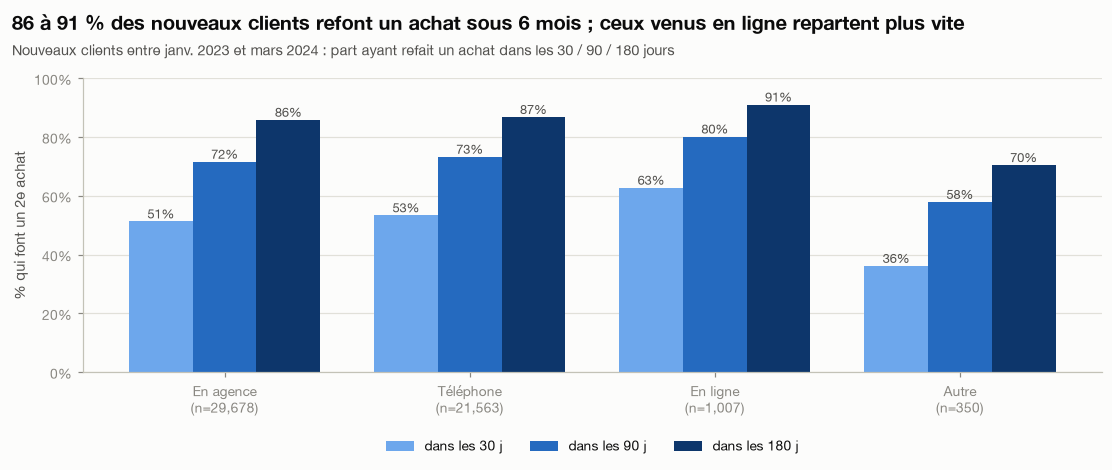

In [27]:
sec = q("""
WITH r AS (SELECT client_id, d, channel, row_number() OVER (PARTITION BY client_id ORDER BY d) AS rn FROM bd),
f AS (SELECT client_id, d AS first_d, channel FROM r WHERE rn = 1 AND d >= DATE '2023-01-01' AND d < DATE '2024-03-22'),
s AS (SELECT client_id, d AS second_d FROM r WHERE rn = 2)
SELECT f.channel, count(*) AS n,
       avg((date_diff('day', first_d, second_d) <= 30)::int) AS r30,
       avg((date_diff('day', first_d, second_d) <= 90)::int) AS r90,
       avg((date_diff('day', first_d, second_d) <= 180)::int) AS r180
FROM f LEFT JOIN s USING (client_id) GROUP BY 1""").set_index("channel")
sec = sec[sec["n"] >= 300].sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
x = np.arange(len(sec))
w = 0.26
for off, col, colr, lab in [(-w, "r30", SEQ[2], "dans les 30 j"), (0, "r90", SEQ[4], "dans les 90 j"), (w, "r180", SEQ[6], "dans les 180 j")]:
    ax.bar(x + off, sec[col], width=w, color=colr, label=lab)
    for xi, v in zip(x + off, sec[col]):
        ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, [f"{CHANNEL_LABEL[c]}\n(n={n_:,.0f})" for c, n_ in zip(sec.index, sec["n"])])
pct_axis(ax)
ax.set_ylim(0, 1)
ax.set_ylabel("% qui font un 2e achat")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
headline(fig, "86 à 91 % des nouveaux clients refont un achat sous 6 mois ; ceux venus en ligne repartent plus vite",
         "Nouveaux clients entre janv. 2023 et mars 2024 : part ayant refait un achat dans les 30 / 90 / 180 jours")
plt.show()

## 7. Où se concentre le churn ?

**Question Q7.** Avec la photo principale (`T_SNAP`), on découpe le taux de churn par les dimensions disponibles. Attention aux **effets de confusion** : fréquence, récence et valeur sont liées entre elles ; on isole donc les clients réguliers quand c'est pertinent.

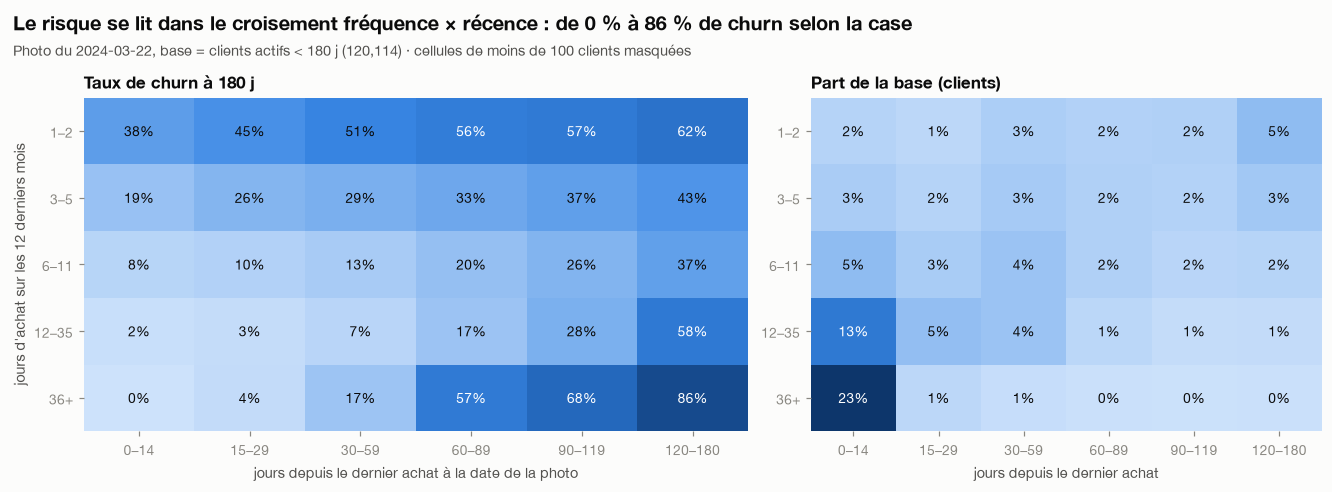

In [28]:
F["freq5"] = pd.cut(F["f365"], [0, 2, 5, 11, 35, np.inf], labels=["1–2", "3–5", "6–11", "12–35", "36+"])
F["rec_bin"] = pd.cut(F["recency"], [-1, 14, 29, 59, 89, 119, 180], labels=["0–14", "15–29", "30–59", "60–89", "90–119", "120–180"])
hm = F.pivot_table(index="freq5", columns="rec_bin", values="churn", aggfunc="mean", observed=False)
hn = F.pivot_table(index="freq5", columns="rec_bin", values="churn", aggfunc="count", observed=False)
hm = hm.where(hn >= 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1]})
heat(axes[0], hm, "Taux de churn à 180 j", vmax=1.0)
axes[0].set_xlabel("jours depuis le dernier achat à la date de la photo")
axes[0].set_ylabel("jours d'achat sur les 12 derniers mois")
hn_pct = hn / hn.to_numpy().sum()
heat(axes[1], hn_pct, "Part de la base (clients)", vmax=hn_pct.to_numpy().max())
axes[1].set_xlabel("jours depuis le dernier achat")
headline(fig, "Le risque se lit dans le croisement fréquence × récence : de 0 % à 86 % de churn selon la case",
         f"Photo du {T_SNAP}, base = clients actifs < {BASE_DAYS} j ({n_base:,.0f}) · cellules de moins de 100 clients masquées")
plt.show()

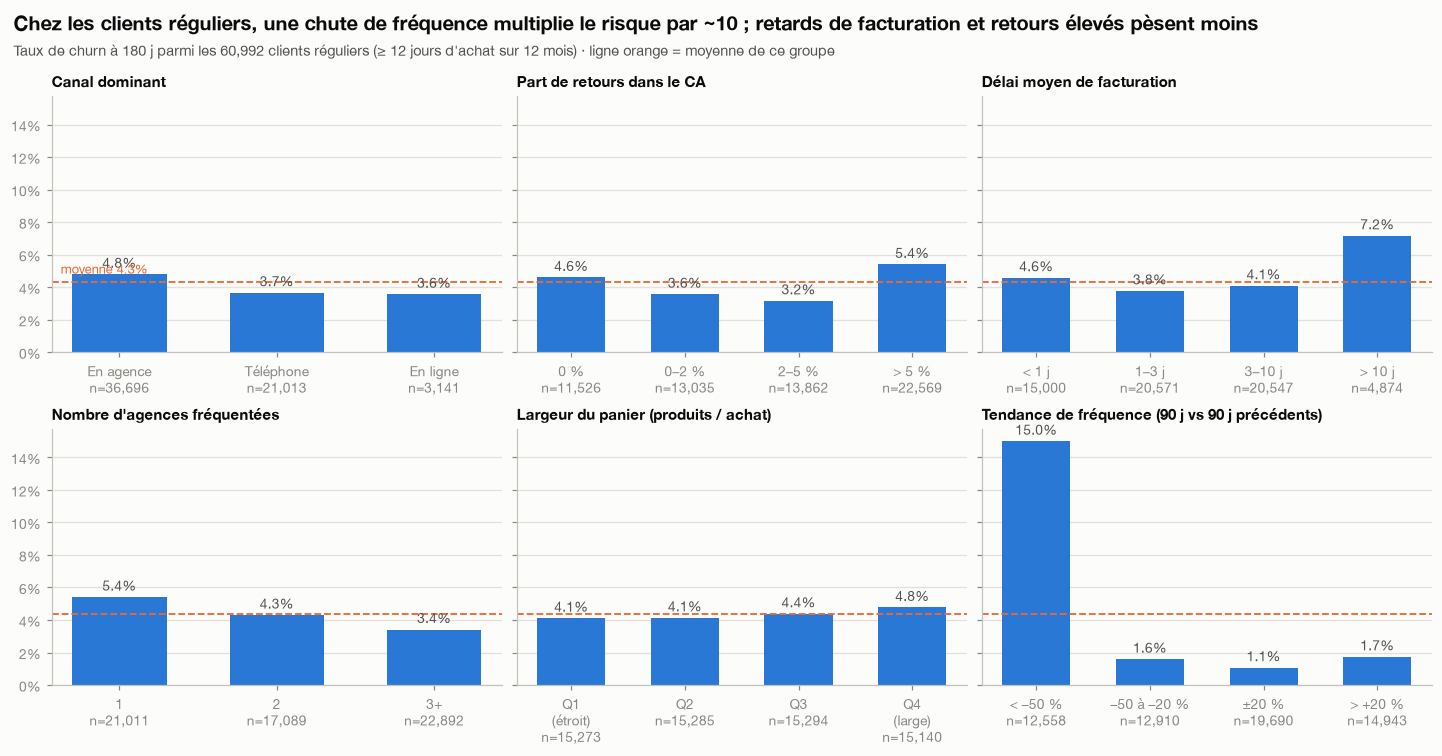

In [29]:
R = F[F["f365"] >= 12].copy()  # regular clients: where retention effort is worth it
R["ret_bin"] = pd.cut(R["ret_share"].fillna(0), [-1, 0, 0.02, 0.05, np.inf], labels=["0 %", "0–2 %", "2–5 %", "> 5 %"])
R["lag_bin"] = pd.cut(R["lag_mean"], [-1, 1, 3, 10, np.inf], labels=["< 1 j", "1–3 j", "3–10 j", "> 10 j"])
R["br_bin"] = pd.cut(R["n_branch"], [0, 1, 2, np.inf], labels=["1", "2", "3+"])
R["breadth_bin"] = pd.qcut(R["basket_breadth"], 4, labels=["Q1\n(étroit)", "Q2", "Q3", "Q4\n(large)"])
ratio = R["f90"] / R["f90_prev"].replace(0, np.nan)
R["trend_bin"] = pd.cut(ratio, [-1, 0.5, 0.8, 1.2, np.inf], labels=["< –50 %", "–50 à –20 %", "±20 %", "> +20 %"])
R["chan_bin"] = R["channel"].map(CHANNEL_LABEL)

panels = [("Canal dominant", "chan_bin", ["En agence", "Téléphone", "En ligne"]),
          ("Part de retours dans le CA", "ret_bin", None), ("Délai moyen de facturation", "lag_bin", None),
          ("Nombre d'agences fréquentées", "br_bin", None), ("Largeur du panier (produits / achat)", "breadth_bin", None),
          ("Tendance de fréquence (90 j vs 90 j précédents)", "trend_bin", None)]
base_rate = R["churn"].mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), constrained_layout=True, sharey=True)
for ax, (ttl, col, keep) in zip(axes.flat, panels):
    g_ = R.groupby(col, observed=True)["churn"].agg(["mean", "count"])
    if keep:
        g_ = g_.loc[[k for k in keep if k in g_.index]]
    g_ = g_[g_["count"] >= 100]
    ax.bar(range(len(g_)), g_["mean"], width=0.6, color=C["blue"])
    for i, (m_, n_) in enumerate(zip(g_["mean"], g_["count"])):
        ax.text(i, m_ + 0.004, f"{m_:.1%}", ha="center", fontsize=9, color=INK2)
    ax.axhline(base_rate, color=C["orange"], lw=1.2, ls="--")
    ax.set_xticks(range(len(g_)), [f"{i}\nn={n_:,.0f}" for i, n_ in zip(g_.index, g_["count"])])
    ax.set_title(ttl, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    pct_axis(ax)
axes[0, 0].text(0.02, base_rate + 0.003, f"moyenne {base_rate:.1%}", transform=axes[0, 0].get_yaxis_transform(), ha="left", fontsize=8.5, color=C["orange"], va="bottom")
headline(fig, "Chez les clients réguliers, une chute de fréquence multiplie le risque par ~10 ; retards de facturation et retours élevés pèsent moins",
         f"Taux de churn à {HORIZON} j parmi les {len(R):,.0f} clients réguliers (≥ 12 jours d'achat sur 12 mois) · ligne orange = moyenne de ce groupe")
plt.show()

**Lecture** (vues univariées, partiellement confondues entre elles) :
- La **chute de fréquence** est de loin le signal le plus fort : un client régulier dont la fréquence a **plus que divisé par 2** sur les 90 derniers jours a **~15 % de risque de départ, contre ~1-2 % ailleurs** (×10). Attention : ce signal est en partie *mécanique* (le groupe « < –50 % » inclut les clients déjà silencieux depuis 90 jours), c'est précisément l'alerte précoce recherchée.
- Un **délai moyen de facturation > 10 jours** (7,2 % vs 4,3 %) et une **part de retours > 5 %** (5,4 %) sont associés à plus de churn : cohérent avec l'hypothèse de la Supply Chain (« délais et ruptures font partir les clients »), mais l'effet reste **secondaire** (×1,3 à ×1,7) et le proxy est imparfait ; il faudra les données de stock / livraison pour le confirmer (UC n°2).
- Les clients **mono-agence** (5,4 %) et en **agence** (4,8 %) churnent un peu plus que les multi-agences (3,4 %) et le téléphone / en ligne (~3,5 %) : l'ancrage multi-points de vente est protecteur.
- La **largeur du panier** n'est pas discriminante.

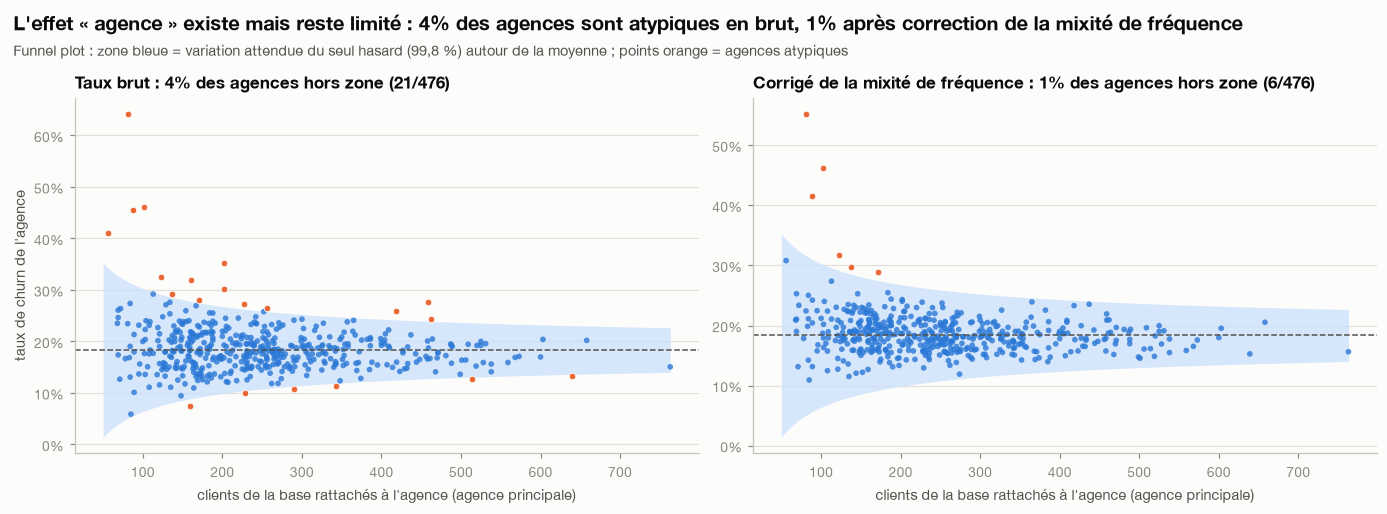

,n,churn,exp,z_adj
home_branch,,,,
10816,81,0.642,0.273,7.450
3627,102,0.461,0.182,7.284
1858,88,0.455,0.222,5.251
3679,123,0.325,0.190,3.806
10126,171,0.281,0.175,3.639


In [30]:
MIN_CL = 50
bt = F.groupby("home_branch").agg(n=("churn", "size"), churn=("churn", "mean"))
# expected churn if the branch had the same frequency mix as the base (indirect standardisation)
class_rate = F.groupby("freq5", observed=True)["churn"].mean()
F["exp"] = F["freq5"].map(class_rate).astype(float)
bt["exp"] = F.groupby("home_branch")["exp"].mean()
bt = bt[bt["n"] >= MIN_CL]
p0 = F["churn"].mean()
nn = np.linspace(MIN_CL, bt["n"].max(), 200)
lim95, lim998 = 1.96 * np.sqrt(p0 * (1 - p0) / nn), 3.09 * np.sqrt(p0 * (1 - p0) / nn)
bt["z_raw"] = (bt["churn"] - p0) / np.sqrt(p0 * (1 - p0) / bt["n"])
bt["z_adj"] = (bt["churn"] - bt["exp"]) / np.sqrt(bt["exp"] * (1 - bt["exp"]) / bt["n"])
out_raw, out_adj = (bt["z_raw"].abs() > 3.09).mean(), (bt["z_adj"].abs() > 3.09).mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), constrained_layout=True)
for ax, ycol, center, ttl, zcol in [(axes[0], bt["churn"], p0, "Taux brut", "z_raw"), (axes[1], bt["churn"] - bt["exp"] + p0, p0, "Corrigé de la mixité de fréquence", "z_adj")]:
    out = bt[zcol].abs() > 3.09
    ax.fill_between(nn, center - lim998, center + lim998, color=SEQ[0], alpha=0.8, lw=0)
    ax.scatter(bt.loc[~out, "n"], ycol[~out], s=14, color=C["blue"], alpha=0.8, edgecolors="none")
    ax.scatter(bt.loc[out, "n"], ycol[out], s=18, color=C["orange"], edgecolors=SURF, linewidths=0.5)
    ax.axhline(center, color=INK2, lw=1, ls="--")
    pct_axis(ax)
    ax.set_xlabel("clients de la base rattachés à l'agence (agence principale)")
    ax.set_title(f"{ttl} : {out.mean():.0%} des agences hors zone ({out.sum()}/{len(bt)})")
axes[0].set_ylabel("taux de churn de l'agence")
headline(fig, f"L'effet « agence » existe mais reste limité : {out_raw:.0%} des agences sont atypiques en brut, {out_adj:.0%} après correction de la mixité de fréquence",
         "Funnel plot : zone bleue = variation attendue du seul hasard (99,8 %) autour de la moyenne ; points orange = agences atypiques")
plt.show()
bt.sort_values("z_adj", ascending=False)[["n", "churn", "exp", "z_adj"]].head(5)

**Lecture** : en brut, ~4 % des agences sortent de l'intervalle attendu (le hasard n'en expliquerait que ~0,2 %) ; une fois la **mixité de fréquence** des clients prise en compte, il n'en reste que **~1 %** (une demi-douzaine d'agences, de petite taille, avec 30 à 65 % de churn). L'effet agence est donc **réel mais faible** : l'essentiel de la variation entre agences vient de la composition de leur clientèle. Ces quelques agences atypiques sont néanmoins de bons candidats pour le pilote (ou à investiguer côté ruptures / concurrence locale). Attention à l'attribution client → agence (section 3 : près de la moitié des clients sont multi-agences).

## 8. Signaux avant-coureurs dans les transactions

**Question Q8.** Le Sales Manager craint que « la data soit trop réductrice » ; la Data team rappelle qu'il n'y a que des transactions. Quels signaux ces transactions contiennent-elles *avant* le départ ? On compare, sur les 12 mois précédant la photo, les clients **actifs récemment** (< 90 j) et **réguliers** (≥ 6 jours d'achat) qui partiront ou resteront.

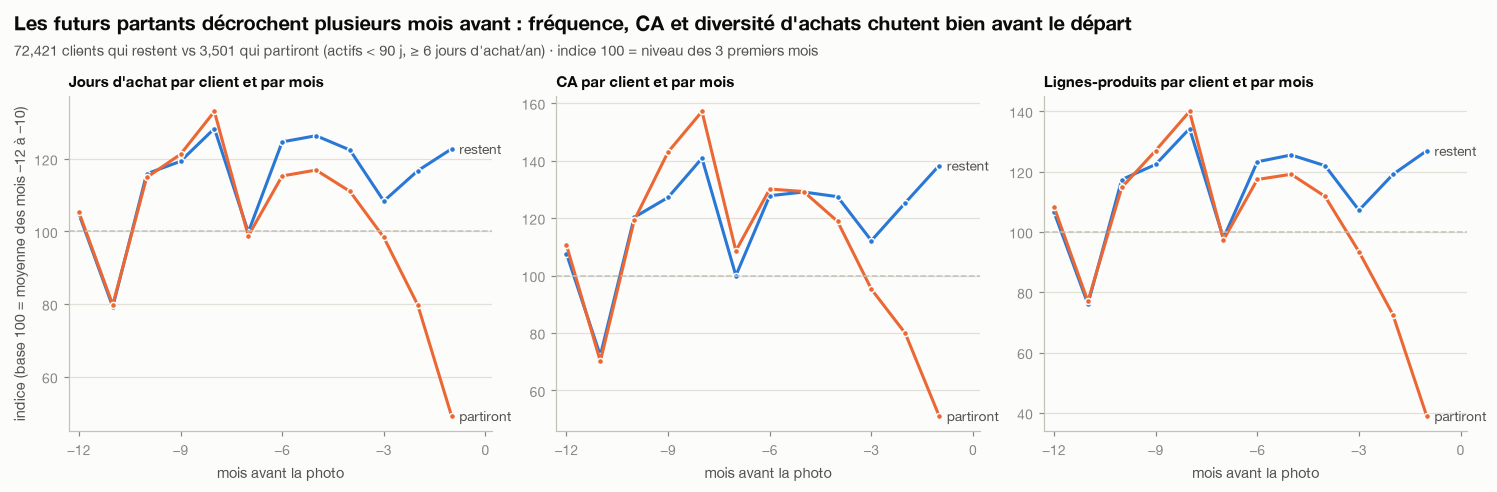

In [31]:
traj = q(f"""
SELECT f.churn, floor((date_diff('day', b.d, DATE '{T_SNAP}') - 1) / 30)::int AS bk,
       count(*) AS pdays, sum(b.rev_pos) AS rev, sum(b.n_prod) AS prods
FROM bd b JOIN feat f USING (client_id)
WHERE b.d < DATE '{T_SNAP}' AND b.d >= DATE '{T_SNAP}' - 360 AND f.recency <= 90 AND f.f365 >= 6
GROUP BY 1, 2""")
ng = q("SELECT churn, count(*) AS n FROM feat WHERE recency <= 90 AND f365 >= 6 GROUP BY 1").set_index("churn")["n"]
traj["months_before"] = -(traj["bk"] + 1)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), constrained_layout=True, sharex=True)
for ax, col, ttl in zip(axes, ["pdays", "rev", "prods"], ["Jours d'achat par client et par mois", "CA par client et par mois", "Lignes-produits par client et par mois"]):
    for churn_flag, colr, lab in [(False, C["blue"], "restent"), (True, C["orange"], "partiront")]:
        d = traj[traj["churn"] == churn_flag].sort_values("months_before")
        v = d[col] / ng[churn_flag]
        ref = v[d["months_before"] <= -10].mean()
        ax.plot(d["months_before"], 100 * v / ref, color=colr, marker="o", ms=4, mec=SURF, mew=1)
        label_end(ax, d["months_before"].iloc[-1], 100 * v.iloc[-1] / ref, lab, dx=5)
    ax.axhline(100, color=AXIS, lw=1, ls="--")
    ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("mois avant la photo")
    ax.set_xlim(-12.3, 0.2)
    ax.set_xticks(range(-12, 1, 3))
axes[0].set_ylabel("indice (base 100 = moyenne des mois –12 à –10)")
n_f, n_r = ng[True], ng[False]
headline(fig, "Les futurs partants décrochent plusieurs mois avant : fréquence, CA et diversité d'achats chutent bien avant le départ",
         f"{n_r:,.0f} clients qui restent vs {n_f:,.0f} qui partiront (actifs < 90 j, ≥ 6 jours d'achat/an) · indice 100 = niveau des 3 premiers mois")
plt.show()

Les clients qui partiront **achètent moins souvent, moins cher et moins varié** dès ~5 mois avant la photo, avec une chute franche sur les 3 derniers mois, alors que ceux qui restent sont stables (les creux communs aux deux courbes aux mois –11 et –7 sont les creux saisonniers de mai et septembre 2023). Une partie du décrochage du dernier mois est mécanique (par définition, ces clients n'achètent plus ensuite), mais la **baisse débute bien avant** : un signal d'**alerte précoce** présent dans les transactions seules — contrairement à l'idée que le départ serait « imprévisible ».

### Pouvoir prédictif de chaque variable prise isolément
Un AUC (aire sous la courbe ROC) de 0,5 = aucune information, 1,0 = séparation parfaite. Ce n'est **pas un modèle** mais un classement des pistes de features, avant d'en tirer un vrai.

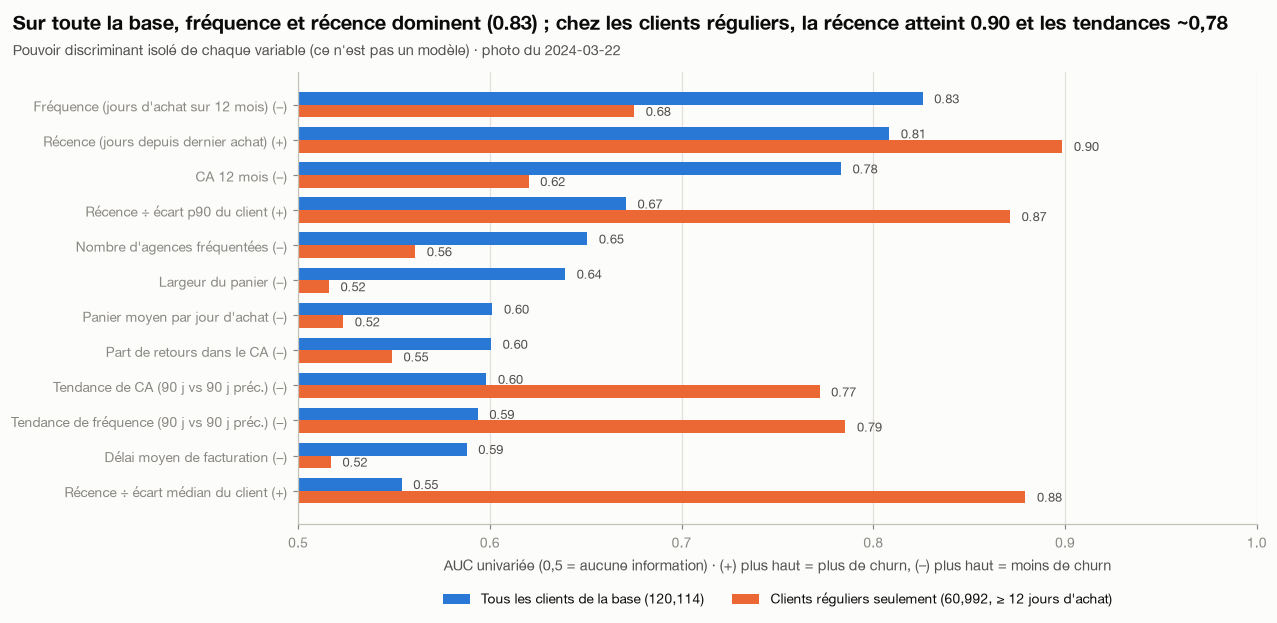

,tous,reguliers
Récence (jours depuis dernier achat),0.808,0.899
Récence ÷ écart médian du client,0.554,0.879
Récence ÷ écart p90 du client,0.671,0.871
Tendance de fréquence (90 j vs 90 j préc.),0.594,0.785
Tendance de CA (90 j vs 90 j préc.),0.598,0.772
Fréquence (jours d'achat sur 12 mois),0.826,0.675
CA 12 mois,0.783,0.620
Nombre d'agences fréquentées,0.651,0.561
Part de retours dans le CA,0.601,0.549
Panier moyen par jour d'achat,0.601,0.524


In [32]:
X = pd.DataFrame(index=F.index)
mg = F["med_gap"].fillna(180).clip(lower=1)
p90 = F["p90_gap"].fillna(180).clip(lower=1)
X["Récence (jours depuis dernier achat)"] = F["recency"]
X["Récence ÷ écart médian du client"] = F["recency"] / mg
X["Récence ÷ écart p90 du client"] = F["recency"] / p90
X["Fréquence (jours d'achat sur 12 mois)"] = F["f365"]
X["CA 12 mois"] = F["rev365"]
X["Panier moyen par jour d'achat"] = F["avg_basket"]
X["Tendance de fréquence (90 j vs 90 j préc.)"] = (F["f90"] - F["f90_prev"]) / (F["f90"] + F["f90_prev"]).replace(0, np.nan)
X["Tendance de CA (90 j vs 90 j préc.)"] = (F["rev90"] - F["rev90_prev"]) / (F["rev90"] + F["rev90_prev"]).replace(0, np.nan)
X["Part de retours dans le CA"] = F["ret_share"].fillna(0)
X["Délai moyen de facturation"] = F["lag_mean"]
X["Largeur du panier"] = F["basket_breadth"]
X["Nombre d'agences fréquentées"] = F["n_branch"]
X = X.fillna(X.median())


def auc(y, sc):
    r = pd.Series(sc, index=y.index).rank()
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


y_ = F["churn"].astype(int)
reg = F["f365"] >= 12
au_all = pd.Series({c: auc(y_, X[c]) for c in X.columns})
au_reg = pd.Series({c: auc(y_[reg], X.loc[reg, c]) for c in X.columns})
res = pd.DataFrame({"tous": (au_all - 0.5).abs() + 0.5, "reguliers": (au_reg - 0.5).abs() + 0.5, "plus_haut_egal_plus_de_churn": au_all >= 0.5}).sort_values("tous")

fig, ax = plt.subplots(figsize=(11.5, 5), constrained_layout=True)
yy = np.arange(len(res))
h = 0.36
ax.barh(yy + h / 2, res["tous"] - 0.5, left=0.5, height=h, color=C["blue"], label=f"Tous les clients de la base ({n_base:,.0f})")
ax.barh(yy - h / 2, res["reguliers"] - 0.5, left=0.5, height=h, color=C["orange"], label=f"Clients réguliers seulement ({int(reg.sum()):,.0f}, ≥ 12 jours d'achat)")
for yi, a_, r_ in zip(yy, res["tous"], res["reguliers"]):
    ax.text(a_ + 0.006, yi + h / 2, f"{a_:.2f}", va="center", fontsize=8.5, color=INK2)
    ax.text(r_ + 0.006, yi - h / 2, f"{r_:.2f}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(yy, [f"{n_} ({'+' if sgn else '–'})" for n_, sgn in zip(res.index, res["plus_haut_egal_plus_de_churn"])])
ax.axvline(0.5, color=INK2, lw=1)
ax.set_xlim(0.5, 1.0)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC univariée (0,5 = aucune information) · (+) plus haut = plus de churn, (–) plus haut = moins de churn")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
headline(fig, f"Sur toute la base, fréquence et récence dominent ({res['tous'].max():.2f}) ; chez les clients réguliers, la récence atteint {res['reguliers'].max():.2f} et les tendances ~0,78",
         f"Pouvoir discriminant isolé de chaque variable (ce n'est pas un modèle) · photo du {T_SNAP}")
plt.show()
res[["tous", "reguliers"]].sort_values("reguliers", ascending=False)

**Lecture** — à ne pas surinterpréter (AUC univarié, pas de modèle) :
- Sur **toute la base**, ce sont la **fréquence**, la **récence** et le **CA** qui dominent. Ils mesurent surtout la **taille / régularité** du client : les petits clients occasionnels partent plus, ce qui est facile à prédire mais **peu intéressant commercialement**.
- La **récence rapportée à l'écart médian du client** est un cas d'école : AUC **0,88** chez les clients réguliers, mais seulement **0,55** sur toute la base. Pour un client occasionnel (peu d'achats) le rythme n'est pas estimable (valeur imputée, écarts instables) et le ratio n'a aucun sens. À retenir pour le feature engineering : les variables de rythme doivent être **calculées seulement quand l'historique le permet** (≥ 6 achats) et combinées à la fréquence ; un modèle à arbres gère cela naturellement.
- Même chez les réguliers, la **récence brute** reste la meilleure variable en AUC (0,90) : les variables relatives n'apportent leur valeur que lorsqu'on pondère par le **CA** (cf. section 9).
- Les **retours, le délai de facturation et la largeur de panier** discriminent peu (AUC 0,52-0,60) ; la **tendance de fréquence / de CA** devient utile chez les clients réguliers (AUC ~0,78).
- Un modèle multivarié (gradient boosting par exemple) combinera ces signaux ; il sera à évaluer **par segment de fréquence et en valeur**, pas seulement en AUC global.

## 9. Quelle liste d'action est réaliste ? Le « score à battre »

**Question Q9.** ~200 commerciaux, une visite coûte ~4 h (3 h + 1 h de suivi), le téléphone est « le meilleur » canal. Une liste de clients à rappeler doit donc être **courte et précise**. On teste le **score le plus simple possible** (une seule variable), qu'un modèle devra clairement battre pour justifier sa complexité.

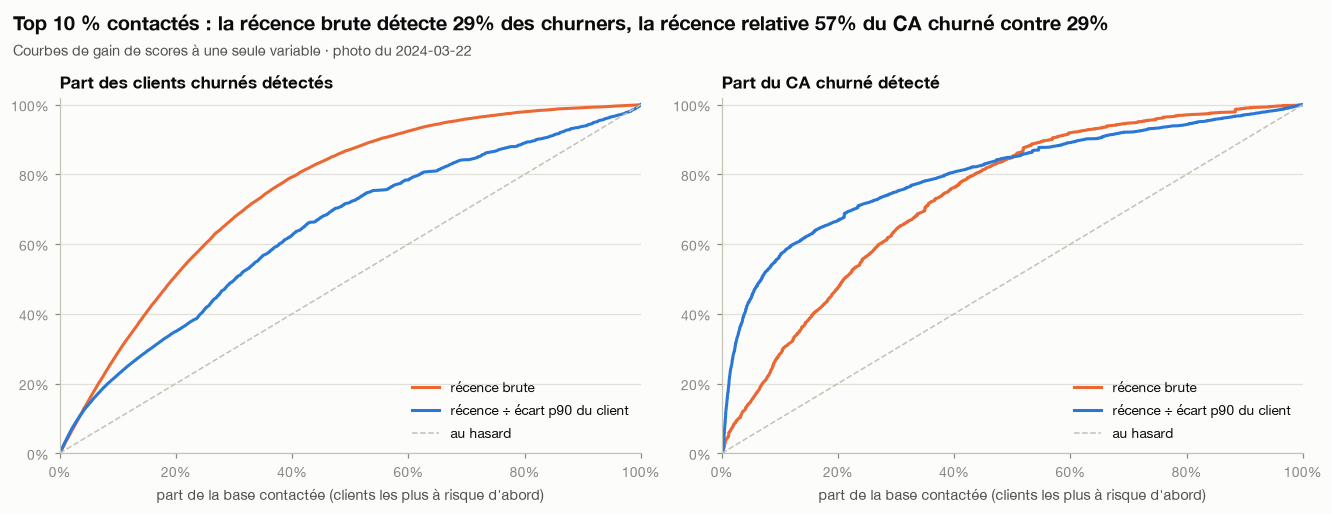

part_de_la_base precision churners_detectes ca_churn_detecte clients_par_commercial heures_par_commercial_si_visites
score                         taille_liste                                                                                                                     
récence brute                 2000                      2%       57%                5%               7%                     10                               40
                              5000                      4%       56%               13%              13%                     25                              100
                              10000                     8%       54%               24%              23%                     50                              200
                              20000                    17%       49%               44%              41%                    100                              400
récence ÷ écart p90 du client 2000                      2%       62%                6%              25%                     10                               40
                              5000                      4%       54%               12%              41%                     25                              100
                              10000                     8%       44%               20%              53%                     50                              200
                              20000                    17%       34%               31%              64%                    100                              400

In [33]:
sc = pd.DataFrame({"churn": F["churn"].to_numpy(), "rev": F["rev365"].to_numpy(), "recency": F["recency"].to_numpy(),
                   "rel90": (F["recency"] / p90).to_numpy(), "rel50": (F["recency"] / mg).to_numpy()})
SCORES = [("recency", C["orange"], "récence brute"), ("rel90", C["blue"], "récence ÷ écart p90 du client")]


def gain(df, score_col):
    d = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    x_ = (np.arange(len(d)) + 1) / len(d)
    return x_, d["churn"].cumsum() / d["churn"].sum(), (d["rev"] * d["churn"]).cumsum() / (d["rev"] * d["churn"]).sum()


fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, k, ttl in [(axes[0], 1, "Part des clients churnés détectés"), (axes[1], 2, "Part du CA churné détecté")]:
    for col, colr, lab in SCORES:
        out = gain(sc, col)
        ax.plot(out[0], out[k], color=colr, label=lab)
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--", label="au hasard")
    pct_axis(ax)
    pct_axis(ax, "x")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("part de la base contactée (clients les plus à risque d'abord)")
    ax.set_title(ttl)
    ax.legend(loc="lower right")
i10 = int(0.1 * len(sc))
g_rec, g_rel = gain(sc, "recency"), gain(sc, "rel90")
headline(fig, f"Top 10 % contactés : la récence brute détecte {g_rec[1][i10]:.0%} des churners, la récence relative {g_rel[2][i10]:.0%} du CA churné contre {g_rec[2][i10]:.0%}",
         f"Courbes de gain de scores à une seule variable · photo du {T_SNAP}")
plt.show()

rows = []
for col, _, lab in SCORES:
    d = sc.sort_values(col, ascending=False).reset_index(drop=True)
    for N in (2000, 5000, 10000, 20000):
        top_ = d.head(N)
        rows.append(dict(score=lab, taille_liste=N, part_de_la_base=N / len(d), precision=top_["churn"].mean(),
                         churners_detectes=top_["churn"].sum() / d["churn"].sum(),
                         ca_churn_detecte=(top_["rev"] * top_["churn"]).sum() / (d["rev"] * d["churn"]).sum(),
                         clients_par_commercial=N / N_REPS, heures_par_commercial_si_visites=N / N_REPS * 4))
tbl = pd.DataFrame(rows).set_index(["score", "taille_liste"])
for c_ in ["part_de_la_base", "precision", "churners_detectes", "ca_churn_detecte"]:
    tbl[c_] = tbl[c_].map("{:.0%}".format)
tbl["clients_par_commercial"] = tbl["clients_par_commercial"].map("{:.0f}".format)
tbl["heures_par_commercial_si_visites"] = tbl["heures_par_commercial_si_visites"].map("{:.0f}".format)
tbl

**Lecture** : les deux scores simples racontent des histoires **différentes** selon la métrique.
- En **nombre de clients**, la récence brute capte davantage de churners (elle repère les petits clients qui s'éloignent).
- En **valeur**, la récence **rapportée au rythme du client** est bien meilleure : elle repère les gros clients réguliers en rupture de rythme, c'est-à-dire ceux qui valent la peine d'être appelés.
- Le tableau chiffre le compromis **taille de liste ↔ précision ↔ capacité commerciale** : avec ~200 commerciaux, une liste de quelques milliers de clients représente quelques dizaines de clients par commercial (faisable au téléphone ; en visite à ~4 h par client, la charge devient vite lourde).

Un modèle devra donc apporter : (1) une **priorisation par valeur espérée** (probabilité de départ × CA) plutôt que par probabilité seule, (2) une alerte **plus précoce** que le simple silence, (3) une **précision** suffisante pour que les commerciaux — sceptiques et peu adeptes du CRM — jugent la liste crédible dès le premier mois.

## 10. Synthèse : ce que les données disent du use case

*(chiffres pour les paramètres par défaut : photo au 22/03/2024, base = clients actifs < 180 j, churn = aucun achat pendant 180 j)*

### Constats clés
| Thème | Constat | Implication |
|---|---|---|
| **Données** | 63,3 M de lignes, 170,6 k clients, 582 « agences », 22/09/2022 → 22/09/2024 (et non 2026 comme le nom du fichier). 3,8 % de lignes négatives (retours), `date_invoice` bruité, jour de semaine atypique, 3 creux brutaux (mai 23, sept. 23, mai 24), ~100 « agences » de < 50 clients. | Dates d'activité = `date_order` ; jour d'achat = ventes > 0 ; pas de variable jour-de-semaine ; poser les questions de la section 11. |
| **Canaux** | Téléphone = 64 % du CA (40 % des lignes) ; en ligne = 9 % du CA (≠ « quasi nul » des interviews) ; visite commercial = 0,05 % des lignes. | Le téléphone est le canal naturel d'une campagne de rétention ; l'effet d'une visite est **invisible** dans les données → pilote avec groupe témoin. |
| **Clients** | Base très concentrée : 1 % des clients = 31 % du CA ; les 13 % à 104+ jours d'achat = 76 % du CA ; les 26 % à 1-3 jours = < 1 %. 47 % multi-agences, 67 % multi-canaux. | Un seul modèle / une seule définition ne tient pas ; **raisonner par segment de fréquence et en valeur**. |
| **Rythme d'achat** | Écart médian 3 j, p95 = 36 j, p99 = 126 j ; l'écart typique varie d'un facteur ~20 selon le client. | Pas de seuil universel ; définition de churn **choisie** (180 j / 180 j) et justifiée. |
| **Taux de churn** | 18 % des clients actifs partent par semestre (stable dans le temps) mais seulement **~3 % du CA** ; décile de CA le plus bas : 53 % de churn ; le plus haut : 2 % (mais 35 % du CA churné). | La valeur à protéger est dans le haut de la base ; évaluer le modèle **en CA**. |
| **Chiffrage d'équipe** | CA perdu avec les clients perdus : **3,4 à 4,8 %** (mesuré) contre 5 / **8** / 12 % (hypothèses) → ~13-18 M de marge/an au lieu de 30,6 M à détection / rétention constantes. | **Revoir l'hypothèse centrale** dans `ClientCo_priorisation_use_cases-2.xlsx`. |
| **Érosion** | Les reculs > 20 % (–469 M) sont presque compensés par des hausses (+448 M) ; mais un recul > 50 % est durable pour ~62 % des clients concernés. | Envisager un 2e label « chute durable de CA » en complément du churn total. |
| **Nouveaux clients** | ~1/3 rachète le mois suivant, 86-91 % refont un achat sous 6 mois. | Phase d'intégration à part ; données pauvres. |
| **Signaux** | Chez les réguliers, une chute de fréquence > 50 % sur 90 j = ~15 % de churn (vs 1-2 %) ; les futurs partants décrochent ~5 mois avant ; AUC de la récence ≈ 0,90 chez les réguliers. Retours / délais de facturation : signaux secondaires. | Le churn **est** prévisible dans les transactions, au moins pour les clients réguliers ; l'hypothèse « ruptures / délais » n'est pas testable sans données de stock. |
| **Effet agence** | ~1 % d'agences atypiques une fois corrigée la mixité de fréquence. | Effet local limité ; utile pour choisir des agences pilotes. |
| **Score à battre** | Top 10 % par « récence ÷ écart p90 » : 57 % du CA churné détecté (contre 28 % pour la récence brute) ; mais 29 % des churners seulement par récence brute… | Le modèle doit viser **la valeur espérée**, pas seulement l'AUC. |

### Implications pour la modélisation (prochaine étape)
1. **Cible** : churn à 180 j parmi les actifs 180 j (+ variante « chute durable > 50 % du CA »).
2. **Découpage temporel strict** : plusieurs photos mensuelles, entraînement sur les plus anciennes, validation / test sur les plus récentes (jamais de découpage aléatoire par ligne : fuite temporelle et clients répétés).
3. **Features** : récence, fréquence, CA, écarts d'achat (p50 / p90 / max), tendances 30/90/180 j, retours, délai de facturation, mix canal, nombre d'agences, largeur de panier, saisonnalité (mois, **pas** le jour de semaine), indicateur « historique suffisant ».
4. **Métriques** : PR-AUC et lift@top-k, **rappel pondéré par le CA**, calibration, performance **par segment de fréquence** ; valeur espérée = P(départ) × CA × taux de rétention.
5. **Déploiement** : liste courte (quelques milliers de clients), priorisée par valeur espérée, par téléphone d'abord ; pilote sur quelques agences avec témoins ; mesurer l'effet **en CA** (réponse directe au besoin « clear success measurement »).

### Limites de cette exploration
- Un « client perdu » ici peut avoir simplement acheté dans une agence **hors périmètre** du dataset (sous-ensemble d'agences / clients) : le churn est possiblement **surestimé**.
- Les clients sous contrat long terme, les institutions publiques (appels d'offres) et les grands comptes gérés centralement **ne sont pas identifiables** : leur « inactivité » n'a pas la même signification.
- Les chiffres de sensibilité dépendent de la définition retenue ; les hypothèses de détection (50 %) et de rétention (20 %) du chiffrage n'ont **aucune mesure** dans ces données.
- Les effets univariés de la section 7 sont partiellement confondus entre eux ; seul un modèle multivarié les démêlera.

## 11. Questions à poser au tutorat BCG / à la Data team ClientCo
1. Pourquoi les dates vont-elles de 2022 à 2024 alors que le fichier est « 2026 » ? Le décalage de +5 ans du notebook d'origine est-il à appliquer ?
2. Quelle devise (Key Facts : $, Financials : EUR) ? Les CA du dataset sont-ils en devise locale ?
3. Que sont les ~100 « agences » de < 50 clients, quasi exclusivement au téléphone (centres d'appels, comptes clés) ?
4. Qu'est-ce qui explique le creux de mi-septembre 2023 (jours fériés ? incident de données ?) ?
5. Une ligne négative est-elle un retour, un avoir ou une correction ? Pourquoi `quantity` ≥ 3 partout ?
6. Que représente `date_invoice` (facture, livraison ?) et pourquoi déborde-t-elle jusqu'en 2026 ?
7. Comment le dataset a-t-il été échantillonné (agences / clients) ? Un client peut-il acheter hors périmètre ?
8. Peut-on marquer les clients sous contrat, institutions publiques et grands comptes centralisés ?
9. Les visites commerciales sont-elles réellement saisies (0,05 % des lignes en « during the visit of a sales rep ») ?